# BIG DATA — SEMANA 07
## EDA responsable y gobierno de datos con Dota 2

**Curso:** Big Data — Universidad Nacional de Juliaca (UNAJ)  
**Docente:** Mg. Leibnihtz Abrahan Ayamamani Choque  
**Semestre:** 2026-2  
**Dataset:** *Dota 2 Matches* — Kaggle (`devinanzelmo/dota-2-matches`)  
**Arquitectura:** Kaggle → Bronze (datos originales) → Silver (tabla analítica validada) → Gold (indicadores)

> La unidad de análisis principal es un jugador dentro de una partida. Este notebook distingue controles de calidad, transformaciones y productos analíticos para mantener trazabilidad y evitar afirmar causalidad a partir de asociaciones.

## Objetivos de aprendizaje

Al finalizar, el estudiante podrá:

1. descargar un dataset real desde Kaggle de forma reproducible y sin exponer credenciales;
2. implementar las capas **Bronze, Silver y Gold**;
3. describir la unidad de observación, el significado y la escala de las variables;
4. interpretar `describe()` en lugar de limitarse a mostrarlo;
5. evaluar dimensiones de calidad aplicables de **DAMA-DMBOK**: completitud, unicidad, validez, consistencia, precisión/plausibilidad y oportunidad;
6. analizar asociaciones, sesgos y variables confusoras sin confundir correlación con causalidad.

### Flujo del notebook

| Etapa | Resultado |
|---|---|
| Preparación | Rutas y dependencias verificadas |
| Bronze | CSV originales de Kaggle, manifiesto y hash SHA-256 |
| Silver | Tabla jugador-partida integrada, tipada y validada |
| Perfilado | Diccionario de datos, `describe()` y calidad DAMA |
| EDA | Distribuciones, grupos, correlaciones y normalización |
| Gold | KPIs y agregados listos para consumo |
| Cierre | Hallazgos, evidencia, interpretación y limitaciones |

---
## 0. Preparación reproducible

El notebook está diseñado para ejecutarse desde cualquier subcarpeta del repositorio `EDA`. No instala paquetes dentro del notebook: usa el entorno del proyecto y falla con un mensaje claro si falta una dependencia.

### Credenciales de Kaggle

1. En Kaggle abre **Settings → API → Create New Token**.
2. Guarda `kaggle.json` en `C:\Users\TU_USUARIO\.kaggle\kaggle.json` (Windows) o `~/.kaggle/kaggle.json` (Linux/macOS).
3. No copies el token al repositorio ni lo muestres en pantalla.

La celda de descarga es idempotente: si los CSV ya existen en Bronze no vuelve a descargarlos, salvo que `FORCE_DOWNLOAD=True`.

In [8]:
# Celda 0.1: localizar la raíz del proyecto y definir capas
import hashlib
import importlib.util
import json
import os
import platform
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path


def find_project_root(start: Path) -> Path:
    """Localiza la raíz por sus carpetas data/ y notebooks/."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto EDA.")


PROJECT_ROOT = find_project_root(Path.cwd())
BRONZE_DIR = PROJECT_ROOT / "data" / "bronze" / "dota2"
SILVER_DIR = PROJECT_ROOT / "data" / "silver" / "dota2"
GOLD_DIR = PROJECT_ROOT / "data" / "gold" / "dota2"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "dota2"

for folder in (BRONZE_DIR, SILVER_DIR, GOLD_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Proyecto : {PROJECT_ROOT}")
print(f"Python   : {sys.version.split()[0]} ({platform.system()})")
print(f"Bronze   : {BRONZE_DIR.relative_to(PROJECT_ROOT)}")
print(f"Silver   : {SILVER_DIR.relative_to(PROJECT_ROOT)}")
print(f"Gold     : {GOLD_DIR.relative_to(PROJECT_ROOT)}")

Proyecto : C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA
Python   : 3.12.10 (Windows)
Bronze   : data\bronze\dota2
Silver   : data\silver\dota2
Gold     : data\gold\dota2


In [9]:
# Celda 0.2: verificar dependencias sin modificar el entorno
REQUIRED = ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "kaggle"]
missing = [pkg for pkg in REQUIRED if importlib.util.find_spec(pkg) is None]

if missing:
    raise ModuleNotFoundError(
        "Faltan dependencias: " + ", ".join(missing) +
        ". Ejecuta desde la raíz: python -m pip install -r requirements.txt"
    )
print("Dependencias verificadas:", ", ".join(REQUIRED))

Dependencias verificadas: pandas, numpy, matplotlib, seaborn, scipy, kaggle


In [10]:
# Celda 0.3: descargar y extraer los CSV directamente en Bronze
DATASET_SLUG = "devinanzelmo/dota-2-matches"
EXPECTED_FILES = {
    "match.csv", "players.csv", "hero_names.csv",
    "item_ids.csv", "cluster_regions.csv"
}
FORCE_DOWNLOAD = False

kaggle_json = Path.home() / ".kaggle" / "kaggle.json"
present = {p.name for p in BRONZE_DIR.glob("*.csv")}

if FORCE_DOWNLOAD or not EXPECTED_FILES.issubset(present):
    if not kaggle_json.is_file():
        raise FileNotFoundError(
            f"No se encontró {kaggle_json}. Descarga kaggle.json desde Kaggle Settings → API."
        )
    command = [
        sys.executable, "-m", "kaggle", "datasets", "download",
        "-d", DATASET_SLUG, "--unzip", "-p", str(BRONZE_DIR)
    ]
    subprocess.run(command, check=True)

missing_csv = sorted(EXPECTED_FILES - {p.name for p in BRONZE_DIR.glob("*.csv")})
if missing_csv:
    raise FileNotFoundError(f"La descarga no produjo los CSV esperados: {missing_csv}")


def sha256(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


manifest = {
    "dataset": DATASET_SLUG,
    "ingested_at_utc": datetime.now(timezone.utc).isoformat(),
    "layer": "bronze",
    "files": [
        {"name": p.name, "bytes": p.stat().st_size, "sha256": sha256(p)}
        for p in sorted(BRONZE_DIR.glob("*.csv"))
    ],
}
(BRONZE_DIR / "manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
)

print("Bronze listo (datos originales, sin transformación):")
for entry in manifest["files"]:
    print(f"  {entry['name']:<25} {entry['bytes'] / 1024**2:8.2f} MiB  SHA-256 {entry['sha256'][:12]}…")

Bronze listo (datos originales, sin transformación):
  ability_ids.csv               0.02 MiB  SHA-256 5d83baf968f0…
  ability_upgrades.csv        178.33 MiB  SHA-256 5ccfd437fcf7…
  chat.csv                     50.26 MiB  SHA-256 5668a07e1771…
  cluster_regions.csv           0.00 MiB  SHA-256 d10e9c055a63…
  hero_names.csv                0.00 MiB  SHA-256 8f61db7f3603…
  item_ids.csv                  0.00 MiB  SHA-256 0832249399f8…
  match.csv                     2.57 MiB  SHA-256 6180283123e6…
  match_outcomes.csv          102.07 MiB  SHA-256 fc4800089181…
  objectives.csv               57.26 MiB  SHA-256 ffeb846e70cc…
  patch_dates.csv               0.00 MiB  SHA-256 bb65a5cb737d…
  player_ratings.csv           39.95 MiB  SHA-256 b02e7644d4dd…
  player_time.csv             303.78 MiB  SHA-256 ac14667b21a9…
  players.csv                 123.92 MiB  SHA-256 8004d9b4ca9b…
  purchase_log.csv            283.02 MiB  SHA-256 1dbe4db73ce0…
  teamfights.csv               11.28 MiB  SHA-256 1

---
## 1. Contexto, alcance y unidad de análisis

Dos equipos de cinco jugadores —Radiant y Dire— compiten en cada partida de Dota 2. El dataset permite relacionar resultados de partida con métricas finales de cada jugador.

### Pregunta de investigación

> ¿Qué variables de desempeño individual se asocian con la victoria en las partidas registradas, y qué controles evitan interpretaciones engañosas?

### Granularidad

- `match.csv`: una fila representa **una partida**.
- `players.csv`: una fila representa **un jugador/slot dentro de una partida**.
- tabla Silver: una fila representa **un jugador/slot enriquecido con datos de la partida y del héroe**.

### Advertencias analíticas

- Asociación no implica causalidad: las métricas son observadas al final de la partida.
- Popularidad no implica efectividad: deben usarse tasas y tamaños mínimos de muestra.
- Totales dependen de la duración: se comparan también métricas por minuto.
- Las posiciones derivadas de `player_slot` son **slots**, no roles oficiales; sus etiquetas son una aproximación didáctica y se tratan como tal.
- El dataset es histórico (2016) y no representa necesariamente el metajuego actual.

---
## 2. Ingesta Bronze y construcción de Silver

Bronze conserva el origen sin modificaciones. Silver integra las fuentes, estandariza tipos, crea variables documentadas y excluye únicamente registros que incumplen reglas críticas explícitas. Las filas rechazadas también se guardan para auditoría.

In [11]:
# Celda 2.1: importar librerías y configurar visualización
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from IPython.display import display
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:.3f}".format)

COLORS = {
    "navy": "#0D2137", "steel": "#2E86AB", "gold": "#F4B942",
    "coral": "#E55B4D", "green": "#27AE60", "teal": "#0E6B8B",
    "gray": "#64748B",
}
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "#F5F9FC",
    "axes.edgecolor": "#CCCCCC", "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 110,
})

print(f"Pandas {pd.__version__} | NumPy {np.__version__}")

Pandas 2.3.3 | NumPy 2.5.3


In [12]:
# Celda 2.2: cargar los CSV originales desde Bronze
matches = pd.read_csv(BRONZE_DIR / "match.csv")
players = pd.read_csv(BRONZE_DIR / "players.csv")
heroes = pd.read_csv(BRONZE_DIR / "hero_names.csv")
items = pd.read_csv(BRONZE_DIR / "item_ids.csv")
regions = pd.read_csv(BRONZE_DIR / "cluster_regions.csv")

datasets = {
    "matches": matches, "players": players, "heroes": heroes,
    "items": items, "regions": regions,
}

for name, frame in datasets.items():
    print(f"{name:<12} → {frame.shape[0]:>8,} filas × {frame.shape[1]:>3} columnas")

matches      →   50,000 filas ×  13 columnas
players      →  500,000 filas ×  73 columnas
heroes       →      112 filas ×   3 columnas
items        →      189 filas ×   2 columnas
regions      →       53 filas ×   2 columnas


In [13]:
# Celda 2.3: inspección de esquema y muestras (evita imprimir datos completos)
for name in ("matches", "players", "heroes"):
    frame = datasets[name]
    print(f"\n{name.upper()} — shape={frame.shape}")
    display(frame.head(3))
    display(frame.dtypes.rename("tipo").to_frame().T)


MATCHES — shape=(50000, 13)


,match_id,start_time,duration,tower_status_radiant,tower_status_dire,barracks_status_dire,barracks_status_radiant,first_blood_time,game_mode,radiant_win,negative_votes,positive_votes,cluster
0,0,1446750112,2375,1982,4,3,63,1,22,True,0,1,155
1,1,1446753078,2582,0,1846,63,0,221,22,False,0,2,154
2,2,1446764586,2716,256,1972,63,48,190,22,False,0,0,132


,match_id,start_time,duration,tower_status_radiant,tower_status_dire,barracks_status_dire,barracks_status_radiant,first_blood_time,game_mode,radiant_win,negative_votes,positive_votes,cluster
tipo,int64,int64,int64,int64,int64,int64,int64,int64,int64,bool,int64,int64,int64



PLAYERS — shape=(500000, 73)


,match_id,account_id,hero_id,player_slot,gold,gold_spent,gold_per_min,xp_per_min,kills,deaths,assists,denies,last_hits,stuns,hero_damage,hero_healing,tower_damage,item_0,item_1,item_2,item_3,item_4,item_5,level,leaver_status,xp_hero,xp_creep,xp_roshan,xp_other,gold_other,gold_death,gold_buyback,gold_abandon,gold_sell,gold_destroying_structure,gold_killing_heros,gold_killing_creeps,gold_killing_roshan,gold_killing_couriers,unit_order_none,unit_order_move_to_position,unit_order_move_to_target,unit_order_attack_move,unit_order_attack_target,unit_order_cast_position,unit_order_cast_target,unit_order_cast_target_tree,unit_order_cast_no_target,unit_order_cast_toggle,unit_order_hold_position,unit_order_train_ability,unit_order_drop_item,unit_order_give_item,unit_order_pickup_item,unit_order_pickup_rune,unit_order_purchase_item,unit_order_sell_item,unit_order_disassemble_item,unit_order_move_item,unit_order_cast_toggle_auto,unit_order_stop,unit_order_taunt,unit_order_buyback,unit_order_glyph,unit_order_eject_item_from_stash,unit_order_cast_rune,unit_order_ping_ability,unit_order_move_to_direction,unit_order_patrol,unit_order_vector_target_position,unit_order_radar,unit_order_set_item_combine_lock,unit_order_continue
0,0,0,86,0,3261,10960,347,362,9,3,18,1,30,76.736,8690,218,143,180,37,73,56,108,0,16,0,8840.000,5440.000,NaN,83.000,50.000,-957.000,NaN,NaN,212.000,3120.000,5145.000,1087.000,400.000,NaN,NaN,4070.000,1.000,25.000,416.000,51.000,144.000,3.000,71.000,NaN,188.000,16.000,NaN,NaN,NaN,2.000,35.000,2.000,NaN,11.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.000,NaN,NaN,NaN,NaN,NaN,NaN
1,0,1,51,1,2954,17760,494,659,13,3,18,9,109,87.416,23747,0,423,46,63,119,102,24,108,22,0,14331.000,8440.000,2683.000,671.000,395.000,-1137.000,NaN,NaN,1650.000,3299.000,6676.000,4317.000,937.000,NaN,NaN,5894.000,214.000,165.000,1031.000,98.000,39.000,4.000,439.000,NaN,346.000,22.000,NaN,NaN,12.000,52.000,30.000,4.000,NaN,21.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.000,NaN,NaN,NaN,NaN,NaN,NaN
2,0,0,83,2,110,12195,350,385,0,4,15,1,58,NaN,4217,1595,399,48,60,59,108,65,0,17,0,6692.000,8112.000,NaN,453.000,259.000,-1436.000,-1015.000,NaN,NaN,3142.000,2418.000,3697.000,400.000,NaN,NaN,7053.000,3.000,132.000,645.000,36.000,160.000,20.000,373.000,NaN,643.000,17.000,5.000,NaN,7.000,8.000,28.000,NaN,1.000,18.000,NaN,NaN,NaN,1.000,NaN,NaN,NaN,17.000,NaN,NaN,NaN,NaN,NaN,NaN


,match_id,account_id,hero_id,player_slot,gold,gold_spent,gold_per_min,xp_per_min,kills,deaths,assists,denies,last_hits,stuns,hero_damage,hero_healing,tower_damage,item_0,item_1,item_2,item_3,item_4,item_5,level,leaver_status,xp_hero,xp_creep,xp_roshan,xp_other,gold_other,gold_death,gold_buyback,gold_abandon,gold_sell,gold_destroying_structure,gold_killing_heros,gold_killing_creeps,gold_killing_roshan,gold_killing_couriers,unit_order_none,unit_order_move_to_position,unit_order_move_to_target,unit_order_attack_move,unit_order_attack_target,unit_order_cast_position,unit_order_cast_target,unit_order_cast_target_tree,unit_order_cast_no_target,unit_order_cast_toggle,unit_order_hold_position,unit_order_train_ability,unit_order_drop_item,unit_order_give_item,unit_order_pickup_item,unit_order_pickup_rune,unit_order_purchase_item,unit_order_sell_item,unit_order_disassemble_item,unit_order_move_item,unit_order_cast_toggle_auto,unit_order_stop,unit_order_taunt,unit_order_buyback,unit_order_glyph,unit_order_eject_item_from_stash,unit_order_cast_rune,unit_order_ping_ability,unit_order_move_to_direction,unit_order_patrol,unit_order_vector_target_position,unit_order_radar,unit_order_set_item_combine_lock,unit_order_continue
tipo,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64



HEROES — shape=(112, 3)


,name,hero_id,localized_name
0,npc_dota_hero_antimage,1,Anti-Mage
1,npc_dota_hero_axe,2,Axe
2,npc_dota_hero_bane,3,Bane


,name,hero_id,localized_name
tipo,object,int64,object


In [14]:
# Celda 2.4: integrar fuentes y aplicar reglas críticas de Silver
required_match_cols = [
    "match_id", "radiant_win", "duration", "start_time"
]
optional_match_cols = [
    "tower_status_radiant", "tower_status_dire",
    "radiant_score", "dire_score"
]
missing_required = sorted(set(required_match_cols) - set(matches.columns))
if missing_required:
    raise KeyError(f"Faltan columnas obligatorias en match.csv: {missing_required}")

available_optional = [col for col in optional_match_cols if col in matches.columns]
missing_optional = [col for col in optional_match_cols if col not in matches.columns]
match_cols = required_match_cols + available_optional
if missing_optional:
    print(f"Columnas opcionales ausentes (se continúa sin ellas): {missing_optional}")

df_stage = (
    players
    .merge(matches[match_cols], on="match_id", how="left", validate="many_to_one")
    .merge(
        heroes[["hero_id", "localized_name"]],
        on="hero_id", how="left", validate="many_to_one"
    )
)

df_stage["equipo"] = np.where(df_stage["player_slot"] < 128, "Radiant", "Dire")
df_stage["gano"] = (
    ((df_stage["equipo"] == "Radiant") & df_stage["radiant_win"].eq(True)) |
    ((df_stage["equipo"] == "Dire") & df_stage["radiant_win"].eq(False))
)
df_stage["resultado"] = df_stage["gano"].map({True: "win", False: "lose"})
df_stage["duracion_min"] = df_stage["duration"] / 60
df_stage["posicion"] = np.where(
    df_stage["player_slot"] < 128,
    df_stage["player_slot"],
    df_stage["player_slot"] - 128,
)

# Etiquetas didácticas: el slot no prueba el rol real desempeñado.
slot_labels = {
    0: "Slot 0 (aprox. carry)", 1: "Slot 1 (aprox. mid)",
    2: "Slot 2 (aprox. offlane)", 3: "Slot 3 (aprox. support)",
    4: "Slot 4 (aprox. support)",
}
df_stage["pos_nombre"] = df_stage["posicion"].map(slot_labels)
df_stage["kda_ratio"] = (df_stage["kills"] + df_stage["assists"]) / (df_stage["deaths"] + 1)
df_stage["fecha_utc"] = pd.to_datetime(df_stage["start_time"], unit="s", utc=True, errors="coerce")

valid_slots = {0, 1, 2, 3, 4, 128, 129, 130, 131, 132}
critical_ok = (
    df_stage["match_id"].notna()
    & df_stage["player_slot"].isin(valid_slots)
    & df_stage["duration"].between(1, 8999)
    & df_stage["radiant_win"].notna()
)

rejected = df_stage.loc[~critical_ok].copy()
df = df_stage.loc[critical_ok].copy()

# CSV maximiza portabilidad; Parquet conserva tipos si pyarrow está disponible.
silver_csv = SILVER_DIR / "dota2_player_match_silver.csv"
df.to_csv(silver_csv, index=False)
try:
    df.to_parquet(SILVER_DIR / "dota2_player_match_silver.parquet", index=False)
    silver_format = "CSV + Parquet"
except (ImportError, ModuleNotFoundError):
    silver_format = "CSV (instala pyarrow para Parquet)"

if not rejected.empty:
    rejected.to_csv(SILVER_DIR / "rejected_rows.csv", index=False)

print(f"Silver: {len(df):,} filas válidas; {len(rejected):,} rechazadas; formato: {silver_format}")
print(f"Partidas únicas: {df['match_id'].nunique():,}")

Columnas opcionales ausentes (se continúa sin ellas): ['radiant_score', 'dire_score']
Silver: 499,990 filas válidas; 10 rechazadas; formato: CSV + Parquet
Partidas únicas: 49,999


### 2.5 Diccionario de la tabla analítica Silver

El diccionario evita interpretar nombres técnicos por intuición. **Escala** distingue identificadores, categorías, booleanos, fechas, conteos y medidas continuas. Los campos que no participan en el EDA permanecen disponibles en Silver, pero el perfil principal se concentra en las variables relevantes para la pregunta.

In [15]:
# Diccionario de datos de las variables analíticas principales
data_dictionary = pd.DataFrame([
    ("match_id", "Identificador de la partida", "identificador", "No sumar ni promediar"),
    ("player_slot", "Slot del jugador: 0–4 Radiant; 128–132 Dire", "categórica codificada", "Define equipo y slot"),
    ("hero_id", "Identificador del héroe", "identificador", "Se relaciona con hero_names.csv"),
    ("localized_name", "Nombre localizado del héroe", "categórica nominal", "Puede faltar si no hay correspondencia"),
    ("kills", "Héroes enemigos eliminados por el jugador", "conteo", "No implica por sí solo buen desempeño"),
    ("deaths", "Muertes del jugador", "conteo", "Cero es válido"),
    ("assists", "Participaciones en eliminaciones de aliados", "conteo", "Depende del rol y duración"),
    ("gold_per_min", "Oro obtenido por minuto", "razón", "Ya está normalizada por tiempo"),
    ("xp_per_min", "Experiencia obtenida por minuto", "razón", "Ya está normalizada por tiempo"),
    ("hero_damage", "Daño total infligido a héroes", "razón", "Depende de la duración"),
    ("tower_damage", "Daño total infligido a torres", "razón", "Cero es posible"),
    ("hero_healing", "Curación total a héroes", "razón", "Muy dependiente del héroe"),
    ("leaver_status", "Código de abandono; 0 indica finalización normal", "categórica codificada", "No tratar como cantidad"),
    ("radiant_win", "Indicador del equipo ganador", "booleana", "Variable de resultado a nivel partida"),
    ("duration", "Duración de la partida en segundos", "razón", "Se convierte también a minutos"),
    ("start_time", "Inicio de partida en Unix time (UTC)", "temporal", "No analizar como cantidad"),
    ("equipo", "Equipo derivado de player_slot", "categórica nominal", "Radiant o Dire"),
    ("gano", "Victoria del jugador derivada del equipo y radiant_win", "booleana", "Objetivo descriptivo"),
    ("resultado", "Etiqueta legible de gano", "categórica nominal", "win o lose"),
    ("duracion_min", "Duración de partida en minutos", "razón", "Repetida para los 10 jugadores"),
    ("posicion", "Slot 0–4 dentro del equipo", "categórica ordinal aproximada", "No demuestra rol real"),
    ("pos_nombre", "Etiqueta didáctica aproximada del slot", "categórica nominal", "No usar como rol oficial"),
    ("kda_ratio", "(kills + assists) / (deaths + 1)", "razón derivada", "+1 evita división entre cero"),
    ("fecha_utc", "Inicio convertido a fecha UTC", "temporal", "Permite evaluar oportunidad"),
], columns=["columna", "descripcion", "escala", "consideracion"])

display(data_dictionary)
data_dictionary.to_csv(GOLD_DIR / "diccionario_datos.csv", index=False, encoding="utf-8-sig")

,columna,descripcion,escala,consideracion
0,match_id,Identificador de la partida,identificador,No sumar ni promediar
1,player_slot,Slot del jugador: 0–4 Radiant; 128–132 Dire,categórica codificada,Define equipo y slot
2,hero_id,Identificador del héroe,identificador,Se relaciona con hero_names.csv
3,localized_name,Nombre localizado del héroe,categórica nominal,Puede faltar si no hay correspondencia
4,kills,Héroes enemigos eliminados por el jugador,conteo,No implica por sí solo buen desempeño
5,deaths,Muertes del jugador,conteo,Cero es válido
6,assists,Participaciones en eliminaciones de aliados,conteo,Depende del rol y duración
7,gold_per_min,Oro obtenido por minuto,razón,Ya está normalizada por tiempo
8,xp_per_min,Experiencia obtenida por minuto,razón,Ya está normalizada por tiempo
9,hero_damage,Daño total infligido a héroes,razón,Depende de la duración


---
## 3. Perfil descriptivo explicado

`describe()` resume la distribución, pero cada estadístico responde una pregunta distinta:

| Estadístico | Interpretación |
|---|---|
| `count` | observaciones no nulas; compáralo con el total para detectar incompletitud |
| `mean` | promedio, sensible a valores extremos |
| `std` | dispersión respecto del promedio; no tiene sentido para IDs o códigos |
| `min` / `max` | extremos; ayudan a detectar valores imposibles o casos raros |
| `25%`, `50%`, `75%` | cuartiles; `50%` es la mediana y es robusta ante outliers |
| `unique` | número de categorías observadas |
| `top` / `freq` | categoría más frecuente y su frecuencia |

No se deben interpretar promedios de `match_id`, `hero_id`, `player_slot` o `leaver_status`: aunque sean números, funcionan como identificadores o categorías.

In [16]:
# Perfil por columna con interpretación automática y percentil 95
analysis_cols = [
    "kills", "deaths", "assists", "gold_per_min", "xp_per_min",
    "hero_damage", "tower_damage", "hero_healing", "duracion_min", "kda_ratio"
]

describe_numeric = df[analysis_cols].describe(percentiles=[.25, .5, .75, .95]).T
describe_numeric["missing"] = df[analysis_cols].isna().sum()
describe_numeric["skew"] = df[analysis_cols].skew(numeric_only=True)
describe_numeric["cv"] = describe_numeric["std"] / describe_numeric["mean"].replace(0, np.nan)
display(describe_numeric.round(3))

print("LECTURA GUIADA")
for col in analysis_cols:
    s = df[col].dropna()
    relation = "mayor" if s.mean() > s.median() else "menor o igual"
    shape = "sesgo a la derecha" if s.skew() > 0.5 else "sesgo a la izquierda" if s.skew() < -0.5 else "aprox. simétrica"
    print(
        f"• {col}: N={len(s):,}; media={s.mean():.2f}; mediana={s.median():.2f}; "
        f"P95={s.quantile(.95):.2f}; rango=[{s.min():.2f}, {s.max():.2f}]. "
        f"La media es {relation} que la mediana; distribución {shape}."
    )

describe_numeric.to_csv(GOLD_DIR / "perfil_descriptivo_numerico.csv", encoding="utf-8-sig")

,count,mean,std,min,25%,50%,75%,95%,max,missing,skew,cv
kills,499990.000,7.404,5.437,0.000,3.000,6.000,10.000,18.000,59.000,0,1.164,0.734
deaths,499990.000,7.680,3.807,0.000,5.000,8.000,10.000,14.000,42.000,0,0.381,0.496
assists,499990.000,11.762,6.393,0.000,7.000,11.000,16.000,23.000,54.000,0,0.646,0.544
gold_per_min,499990.000,415.097,138.211,100.000,317.000,395.000,496.000,665.000,1601.000,0,0.862,0.333
xp_per_min,499990.000,449.979,146.394,0.000,343.000,443.000,550.000,699.000,1559.000,0,0.266,0.325
hero_damage,499990.000,12234.249,6718.727,0.000,7308.000,10946.000,15873.000,25058.000,68384.000,0,1.085,0.549
tower_damage,499990.000,1313.188,1801.172,0.000,118.000,554.000,1750.000,5311.000,15986.000,0,2.077,1.372
hero_healing,499990.000,466.597,1210.295,0.000,0.000,0.000,214.000,2866.000,19222.000,0,4.007,2.594
duracion_min,499990.000,41.270,10.529,0.983,33.817,40.250,47.867,60.100,111.217,0,0.507,0.255
kda_ratio,499990.000,2.934,2.868,0.000,1.300,2.167,3.571,7.667,57.000,0,3.957,0.978


LECTURA GUIADA
• kills: N=499,990; media=7.40; mediana=6.00; P95=18.00; rango=[0.00, 59.00]. La media es mayor que la mediana; distribución sesgo a la derecha.
• deaths: N=499,990; media=7.68; mediana=8.00; P95=14.00; rango=[0.00, 42.00]. La media es menor o igual que la mediana; distribución aprox. simétrica.
• assists: N=499,990; media=11.76; mediana=11.00; P95=23.00; rango=[0.00, 54.00]. La media es mayor que la mediana; distribución sesgo a la derecha.
• gold_per_min: N=499,990; media=415.10; mediana=395.00; P95=665.00; rango=[100.00, 1601.00]. La media es mayor que la mediana; distribución sesgo a la derecha.
• xp_per_min: N=499,990; media=449.98; mediana=443.00; P95=699.00; rango=[0.00, 1559.00]. La media es mayor que la mediana; distribución aprox. simétrica.
• hero_damage: N=499,990; media=12234.25; mediana=10946.00; P95=25058.00; rango=[0.00, 68384.00]. La media es mayor que la mediana; distribución sesgo a la derecha.
• tower_damage: N=499,990; media=1313.19; mediana=554.00; 

---
## 🔍 Sección 3 — Exploración Inicial

> **Preguntas a responder antes de cualquier análisis:**
> - ¿Qué representa cada fila?
> - ¿Los tipos de datos son los esperados?
> - ¿Hay columnas con nombres ambiguos?
> - ¿El tamaño del dataset es suficiente para comparaciones por héroe/posición?

In [17]:
# ── Celda 3.1: Estructura del DataFrame maestro ───────────────────────────
print("INFORMACIÓN ESTRUCTURAL DEL DATAFRAME MAESTRO")
print("=" * 55)
df.info(memory_usage='deep')

INFORMACIÓN ESTRUCTURAL DEL DATAFRAME MAESTRO
<class 'pandas.core.frame.DataFrame'>
Index: 499990 entries, 0 to 499999
Data columns (total 87 columns):
 #   Column                             Non-Null Count   Dtype              
---  ------                             --------------   -----              
 0   match_id                           499990 non-null  int64              
 1   account_id                         499990 non-null  int64              
 2   hero_id                            499990 non-null  int64              
 3   player_slot                        499990 non-null  int64              
 4   gold                               499990 non-null  int64              
 5   gold_spent                         499990 non-null  int64              
 6   gold_per_min                       499990 non-null  int64              
 7   xp_per_min                         499990 non-null  int64              
 8   kills                              499990 non-null  int64              
 

In [18]:
# ── Celda 3.2: Tamaño y completitud general ───────────────────────────────
print(f"{'Filas totales':.<35} {df.shape[0]:>10,}")
print(f"{'Columnas totales':.<35} {df.shape[1]:>10,}")
print(f"{'Partidas únicas (match_id)':.<35} {df['match_id'].nunique():>10,}")
print(f"{'Héroes únicos':.<35} {df['localized_name'].nunique():>10,}")
print(f"{'Partidas ganadas por Radiant':.<35} {matches['radiant_win'].sum():>10,}")
print(f"{'% ganadas por Radiant':.<35} {matches['radiant_win'].mean()*100:>9.1f}%")
print()

# Distribución de equipo
print("Distribución por equipo:")
print(df['equipo'].value_counts())

# Distribución resultado
print("\nDistribución por resultado:")
print(df['resultado'].value_counts())

Filas totales......................    499,990
Columnas totales...................         87
Partidas únicas (match_id).........     49,999
Héroes únicos......................        110
Partidas ganadas por Radiant.......     25,943
% ganadas por Radiant..............      51.9%

Distribución por equipo:
equipo
Radiant    249995
Dire       249995
Name: count, dtype: int64

Distribución por resultado:
resultado
win     249995
lose    249995
Name: count, dtype: int64


In [19]:
# ── Celda 3.3: Estadística descriptiva inicial ───────────────────────────
#
# PREGUNTAS PARA EL ESTUDIANTE:
#   1. ¿El promedio de kills tiene sentido para un MOBA?
#   2. ¿El mínimo de deaths puede ser 0? ¿Y de gold_per_min?
#   3. ¿El máximo de hero_damage parece razonable?
#   4. ¿Hay diferencia entre la media y la mediana? ¿Por qué importa?

cols_analizar = ['kills', 'deaths', 'assists', 'gold_per_min',
                 'xp_per_min', 'hero_damage', 'tower_damage',
                 'hero_healing', 'duracion_min', 'kda_ratio']

desc = df[cols_analizar].describe(percentiles=[.25, .5, .75, .95]).round(2)
display(desc)

print()
print("📌 INTERPRETACIONES CLAVE:")
print(f"  • Kills promedio: {df['kills'].mean():.1f}  |  mediana: {df['kills'].median():.0f}")
print(f"  • Duración promedio: {df['duracion_min'].mean():.1f} min  |  mediana: {df['duracion_min'].median():.1f} min")
print(f"  • GPM promedio: {df['gold_per_min'].mean():.0f}  |  máximo: {df['gold_per_min'].max():.0f}")
print(f"  • Asimetría duración (skewness): {df['duracion_min'].skew():.3f}")
print()
print("  Si skewness > 0 → cola derecha (partidas largas son outliers superiores)")
print("  Si media > mediana → la media está inflada por valores extremos")

,kills,deaths,assists,gold_per_min,xp_per_min,hero_damage,tower_damage,hero_healing,duracion_min,kda_ratio
count,499990.000,499990.000,499990.000,499990.000,499990.000,499990.000,499990.000,499990.000,499990.000,499990.000
mean,7.400,7.680,11.760,415.100,449.980,12234.250,1313.190,466.600,41.270,2.930
std,5.440,3.810,6.390,138.210,146.390,6718.730,1801.170,1210.300,10.530,2.870
min,0.000,0.000,0.000,100.000,0.000,0.000,0.000,0.000,0.980,0.000
25%,3.000,5.000,7.000,317.000,343.000,7308.000,118.000,0.000,33.820,1.300
50%,6.000,8.000,11.000,395.000,443.000,10946.000,554.000,0.000,40.250,2.170
75%,10.000,10.000,16.000,496.000,550.000,15873.000,1750.000,214.000,47.870,3.570
95%,18.000,14.000,23.000,665.000,699.000,25058.000,5311.000,2866.000,60.100,7.670
max,59.000,42.000,54.000,1601.000,1559.000,68384.000,15986.000,19222.000,111.220,57.000



📌 INTERPRETACIONES CLAVE:
  • Kills promedio: 7.4  |  mediana: 6
  • Duración promedio: 41.3 min  |  mediana: 40.2 min
  • GPM promedio: 415  |  máximo: 1601
  • Asimetría duración (skewness): 0.507

  Si skewness > 0 → cola derecha (partidas largas son outliers superiores)
  Si media > mediana → la media está inflada por valores extremos


---
## 4. Calidad de datos con dimensiones DAMA-DMBOK aplicables

Las dimensiones no se evalúan con una regla universal: cada una necesita criterios vinculados al dominio y a la granularidad.

| Dimensión | Regla aplicada aquí |
|---|---|
| Completitud | porcentaje no nulo por campo crítico |
| Unicidad | `match_id` único en partidas y (`match_id`, `player_slot`) único en jugadores |
| Validez | slots, booleanos, fechas y rangos aceptados |
| Consistencia | 10 jugadores por partida, 5 por equipo y coherencia equipo–resultado |
| Precisión / plausibilidad | métricas no negativas y duración plausible; no equivale a contrastar con la realidad |
| Oportunidad | antigüedad y cobertura temporal; útil históricamente, no para describir el meta actual |

> “Precisión” queda limitada a plausibilidad interna porque no contamos con una fuente independiente para verificar cada registro.

In [47]:
# Cuadro consolidado de calidad; cada indicador conserva numerador y denominador
expected_players = 10
team_counts = df.groupby(["match_id", "equipo"]).size().unstack(fill_value=0)
players_per_match = df.groupby("match_id").size()

quality_rows = [
    ("Completitud", "match_id no nulo", int(df["match_id"].notna().sum()), len(df)),
    ("Completitud", "hero_id no nulo", int(df["hero_id"].notna().sum()), len(df)),
    ("Completitud", "nombre de héroe no nulo", int(df["localized_name"].notna().sum()), len(df)),
    ("Unicidad", "partidas sin match_id duplicado", int(matches["match_id"].nunique()), len(matches)),
    ("Unicidad", "jugador-slot único por partida", int((~players.duplicated(["match_id", "player_slot"])).sum()), len(players)),
    ("Validez", "player_slot permitido", int(players["player_slot"].isin(valid_slots).sum()), len(players)),
    ("Validez", "timestamp convertible", int(df["fecha_utc"].notna().sum()), len(df)),
    ("Consistencia", "partidas con 10 jugadores", int(players_per_match.eq(expected_players).sum()), len(players_per_match)),
    ("Consistencia", "partidas con 5 jugadores por equipo", int(((team_counts.get("Radiant", 0) == 5) & (team_counts.get("Dire", 0) == 5)).sum()), len(team_counts)),
    ("Plausibilidad", "métricas clave no negativas", int((df[["kills", "deaths", "assists", "gold_per_min", "xp_per_min", "hero_damage"]] >= 0).all(axis=1).sum()), len(df)),
    ("Plausibilidad", "duración entre 1 s y <150 min", int(df["duration"].between(1, 8999).sum()), len(df)),
]

quality_report = pd.DataFrame(quality_rows, columns=["dimension", "regla", "cumple", "total"])
quality_report["porcentaje"] = 100 * quality_report["cumple"] / quality_report["total"]
display(quality_report.style.format({"porcentaje": "{:.2f}%"}))

date_min, date_max = df["fecha_utc"].min(), df["fecha_utc"].max()
print(f"Oportunidad: cobertura {date_min:%Y-%m-%d} a {date_max:%Y-%m-%d} (UTC).")
print("Interpretación: apto para análisis histórico del periodo; no representa el estado actual de Dota 2.")

quality_report.to_csv(GOLD_DIR / "reporte_calidad_dama.csv", index=False, encoding="utf-8-sig")

,dimension,regla,cumple,total,porcentaje
0,Completitud,match_id no nulo,499990,499990,100.00%
1,Completitud,hero_id no nulo,499990,499990,100.00%
2,Completitud,nombre de héroe no nulo,499953,499990,99.99%
3,Unicidad,partidas sin match_id duplicado,50000,50000,100.00%
4,Unicidad,jugador-slot único por partida,500000,500000,100.00%
5,Validez,player_slot permitido,500000,500000,100.00%
6,Validez,timestamp convertible,499990,499990,100.00%
7,Consistencia,partidas con 10 jugadores,49999,49999,100.00%
8,Consistencia,partidas con 5 jugadores por equipo,49999,49999,100.00%
9,Plausibilidad,métricas clave no negativas,499990,499990,100.00%


Oportunidad: cobertura 2015-11-05 a 2015-11-18 (UTC).
Interpretación: apto para análisis histórico del periodo; no representa el estado actual de Dota 2.


In [48]:
# ── Celda 4.1: Completitud — valores nulos ────────────────────────────────
print("DIMENSIÓN 1: COMPLETITUD — Valores nulos por columna")
print("=" * 55)

nulos_conteo = df.isnull().sum()
nulos_pct    = (df.isnull().mean() * 100).round(2)
nulos_df     = pd.DataFrame({'Nulos': nulos_conteo, '% Nulos': nulos_pct})

# Solo mostrar columnas con al menos algún nulo
con_nulos = nulos_df[nulos_df['Nulos'] > 0].sort_values('% Nulos', ascending=False)

if len(con_nulos) > 0:
    display(con_nulos)
    print()
    print("📌 INTERPRETACIÓN:")
    print("  • Columnas item_0 a item_5: slots de ítems. Valor 0 = slot vacío, no es un nulo real.")
    print("  • leaver_status: 0 = completó la partida (no es nulo, es categoría válida).")
    print("  • hero_id = 0: jugador sin héroe asignado (posible partida con disconnect).")
else:
    print("✅ No se detectaron valores nulos en el DataFrame maestro.")

DIMENSIÓN 1: COMPLETITUD — Valores nulos por columna


,Nulos,% Nulos
unit_order_none,499984,100.000
unit_order_continue,499990,100.000
unit_order_radar,499990,100.000
unit_order_taunt,499990,100.000
unit_order_patrol,499990,100.000
unit_order_cast_rune,499981,100.000
unit_order_vector_target_position,499990,100.000
unit_order_set_item_combine_lock,499990,100.000
unit_order_move_to_direction,496439,99.290
unit_order_disassemble_item,485438,97.090



📌 INTERPRETACIÓN:
  • Columnas item_0 a item_5: slots de ítems. Valor 0 = slot vacío, no es un nulo real.
  • leaver_status: 0 = completó la partida (no es nulo, es categoría válida).
  • hero_id = 0: jugador sin héroe asignado (posible partida con disconnect).


In [49]:
# ── Celda 4.2: Precisión — rangos válidos del dominio ────────────────────
print("DIMENSIÓN 2: PRECISIÓN — Validación de rangos del dominio")
print("=" * 58)

checks = {
    'duration > 0':           (df['duration'] > 0).all(),
    'duration razonable (<9000s=150min)': (df['duration'] < 9000).all(),
    'kills >= 0':             (df['kills'] >= 0).all(),
    'deaths >= 0':            (df['deaths'] >= 0).all(),
    'gold_per_min >= 0':      (df['gold_per_min'] >= 0).all(),
    'xp_per_min >= 0':        (df['xp_per_min'] >= 0).all(),
    'hero_damage >= 0':       (df['hero_damage'] >= 0).all(),
}

for check, result in checks.items():
    estado = "✅ OK" if result else "❌ FALLO"
    print(f"  {check:<45} {estado}")

# Partidas de duración sospechosamente corta (< 5 minutos = posible remake/abandon)
cortas = matches[matches['duration'] < 300]
print(f"\n  Partidas de duración < 5 min (posibles remakes): {len(cortas):,}")
print(f"  Representan el {len(cortas)/len(matches)*100:.2f}% del total")

DIMENSIÓN 2: PRECISIÓN — Validación de rangos del dominio
  duration > 0                                  ✅ OK
  duration razonable (<9000s=150min)            ✅ OK
  kills >= 0                                    ✅ OK
  deaths >= 0                                   ✅ OK
  gold_per_min >= 0                             ✅ OK
  xp_per_min >= 0                               ✅ OK
  hero_damage >= 0                              ✅ OK

  Partidas de duración < 5 min (posibles remakes): 14
  Representan el 0.03% del total


In [23]:
# ── Celda 4.3: Unicidad — duplicados ─────────────────────────────────────
print("DIMENSIÓN 3: UNICIDAD — Detección de duplicados")
print("=" * 50)

dup_matches = matches.duplicated(subset='match_id').sum()
dup_players = players.duplicated(subset=['match_id', 'player_slot']).sum()

print(f"  match_id duplicados en matches.csv: {dup_matches:,}")
print(f"  (match_id + player_slot) duplicados en players.csv: {dup_players:,}")
print()
print("📌 NOTA: match_id se repite en players.csv porque hay 10 jugadores por partida.")
print("   Eso NO es un error — es la estructura relacional del dataset.")

DIMENSIÓN 3: UNICIDAD — Detección de duplicados
  match_id duplicados en matches.csv: 0
  (match_id + player_slot) duplicados en players.csv: 0

📌 NOTA: match_id se repite en players.csv porque hay 10 jugadores por partida.
   Eso NO es un error — es la estructura relacional del dataset.


In [24]:
# ── Celda 4.4: Validez — player_slot y conversión de timestamp ───────────
print("DIMENSIÓN 4: VALIDEZ — player_slot y start_time")
print("=" * 52)

# Validar player_slot
slots_validos = list(range(0, 5)) + list(range(128, 133))
slots_invalidos = players[~players['player_slot'].isin(slots_validos)]
print(f"  player_slot inválidos (no 0-4 ni 128-132): {len(slots_invalidos):,}")

# Validar y convertir start_time (Unix Timestamp → datetime)
matches['fecha'] = pd.to_datetime(matches['start_time'], unit='s', utc=True)
matches['hora']      = matches['fecha'].dt.hour
matches['dia_semana'] = matches['fecha'].dt.day_name()
matches['anio']      = matches['fecha'].dt.year

print(f"  Rango de fechas del dataset:")
print(f"    Desde: {matches['fecha'].min().strftime('%Y-%m-%d')}")
print(f"    Hasta: {matches['fecha'].max().strftime('%Y-%m-%d')}")
print(f"  Años presentes: {sorted(matches['anio'].unique())}")
print()
print("📌 NOTA: El dataset refleja partidas de un período específico del juego.")
print("   Los cambios de 'patch' (versión) pueden afectar la efectividad de héroes.")
print("   → Sesgo de selección temporal: conclusiones pueden no aplicar a otras versiones.")

DIMENSIÓN 4: VALIDEZ — player_slot y start_time
  player_slot inválidos (no 0-4 ni 128-132): 0
  Rango de fechas del dataset:
    Desde: 2015-11-05
    Hasta: 2015-11-18
  Años presentes: [np.int32(2015)]

📌 NOTA: El dataset refleja partidas de un período específico del juego.
   Los cambios de 'patch' (versión) pueden afectar la efectividad de héroes.
   → Sesgo de selección temporal: conclusiones pueden no aplicar a otras versiones.


In [25]:
# ── Celda 4.5: Detección de outliers — método IQR ────────────────────────
print("DETECCIÓN DE OUTLIERS — Método IQR (Interquartile Range)")
print("=" * 58)
print("Regla: outlier si valor < Q1 - 1.5*IQR  o  valor > Q3 + 1.5*IQR")
print()

def detectar_outliers_iqr(serie):
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    mask = (serie < lower) | (serie > upper)
    return mask, lower, upper

cols_outlier = ['kills', 'deaths', 'gold_per_min', 'xp_per_min',
                'hero_damage', 'hero_healing', 'duracion_min']

reporte_outliers = []
for col in cols_outlier:
    mask, lo, hi = detectar_outliers_iqr(df[col])
    reporte_outliers.append({
        'Columna': col,
        'Q1': df[col].quantile(0.25),
        'Q3': df[col].quantile(0.75),
        'Límite inferior': lo,
        'Límite superior': hi,
        'Outliers (n)': mask.sum(),
        '% del total': f"{mask.mean()*100:.2f}%"
    })

display(pd.DataFrame(reporte_outliers).set_index('Columna').round(2))
print()
print("📌 INTERPRETACIÓN:")
print("  • hero_healing tiene muchos outliers: la mayoría de héroes no cura nada.")
print("    Los supports con alta curación son extremos estadísticos pero válidos en el dominio.")
print("  • No eliminar outliers automáticamente sin consultar el contexto del juego.")

DETECCIÓN DE OUTLIERS — Método IQR (Interquartile Range)
Regla: outlier si valor < Q1 - 1.5*IQR  o  valor > Q3 + 1.5*IQR



,Q1,Q3,Límite inferior,Límite superior,Outliers (n),% del total
Columna,,,,,,
kills,3.000,10.000,-7.500,20.500,13395,2.68%
deaths,5.000,10.000,-2.500,17.500,4683,0.94%
gold_per_min,317.000,496.000,48.500,764.500,8248,1.65%
xp_per_min,343.000,550.000,32.500,860.500,2422,0.48%
hero_damage,7308.000,15873.000,-5539.500,28720.500,11953,2.39%
hero_healing,0.000,214.000,-321.000,535.000,98590,19.72%
duracion_min,33.820,47.870,12.740,68.940,6460,1.29%



📌 INTERPRETACIÓN:
  • hero_healing tiene muchos outliers: la mayoría de héroes no cura nada.
    Los supports con alta curación son extremos estadísticos pero válidos en el dominio.
  • No eliminar outliers automáticamente sin consultar el contexto del juego.


---
## 📊 Sección 5 — Análisis Descriptivo Univariado

El análisis univariado examina **cada variable de forma independiente**. Es el primer nivel del EDA:
- Histogramas → distribución y forma
- Boxplots → quartiles y outliers
- Skewness/Kurtosis → asimetría y apuntalamiento

> **Pregunta clave:** ¿El promedio tiene sentido para esta variable? ¿O la distribución es tan asimétrica que la mediana sería más representativa?

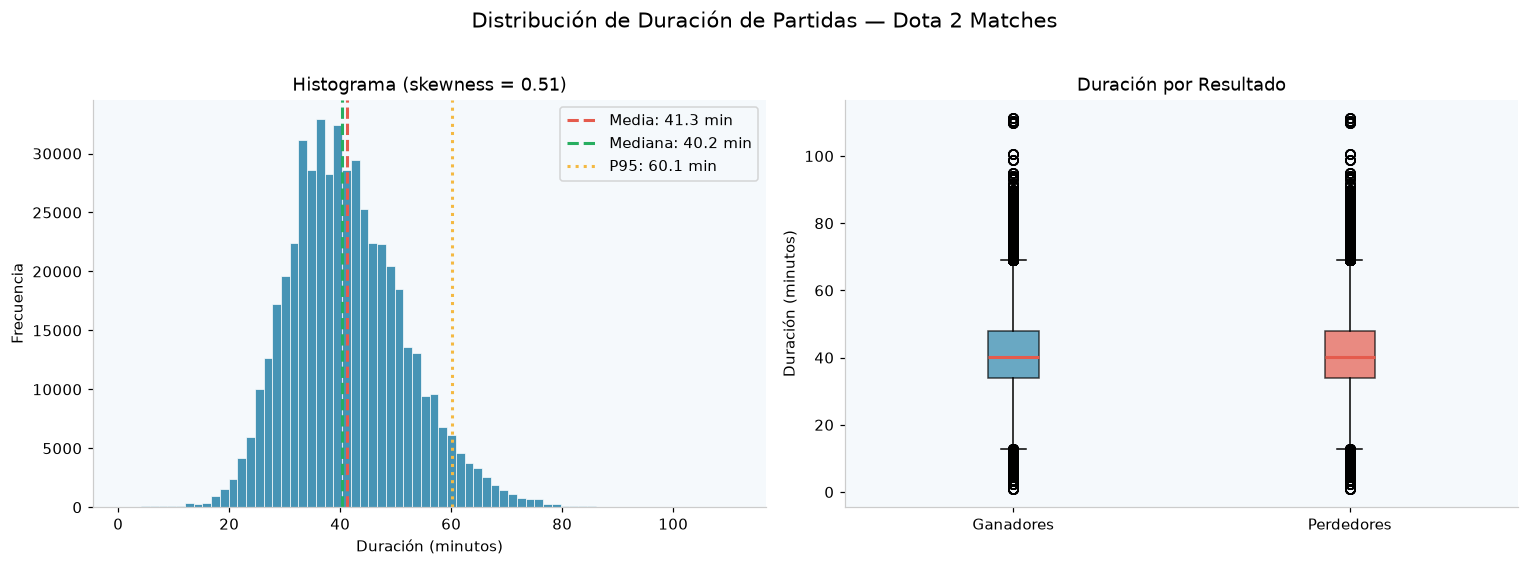


📌 INTERPRETACIÓN:
  • Skewness = 0.51 → distribución con cola derecha (partidas largas son atípicas)
  • Media (41.3) > Mediana (40.2) → media inflada por partidas largas
  • El 95% de las partidas duran menos de 60 minutos
  • ¿La duración difiere entre ganadores y perdedores? → ¿Podría ser una variable confusora?


In [26]:
# ── Celda 5.1: Distribución de duración de partidas ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribución de Duración de Partidas — Dota 2 Matches', fontsize=14, y=1.02)

# Histograma
axes[0].hist(df['duracion_min'].dropna(), bins=70,
             color=COLORS['steel'], edgecolor='white', alpha=0.88, linewidth=0.5)
axes[0].axvline(df['duracion_min'].mean(),
                color=COLORS['coral'], linestyle='--', linewidth=2,
                label=f"Media: {df['duracion_min'].mean():.1f} min")
axes[0].axvline(df['duracion_min'].median(),
                color=COLORS['green'], linestyle='--', linewidth=2,
                label=f"Mediana: {df['duracion_min'].median():.1f} min")
axes[0].axvline(df['duracion_min'].quantile(0.95),
                color=COLORS['gold'], linestyle=':', linewidth=2,
                label=f"P95: {df['duracion_min'].quantile(0.95):.1f} min")
axes[0].set_xlabel('Duración (minutos)')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title(f"Histograma (skewness = {df['duracion_min'].skew():.2f})")
axes[0].legend()

# Boxplot por resultado
data_box = [
    df[df['resultado']=='win']['duracion_min'].dropna(),
    df[df['resultado']=='lose']['duracion_min'].dropna()
]
bp = axes[1].boxplot(data_box, tick_labels=['Ganadores', 'Perdedores'],
                     patch_artist=True, notch=False,
                     boxprops=dict(facecolor=COLORS['light'] if 'light' in COLORS else '#D6EAF8'),
                     medianprops=dict(color=COLORS['coral'], linewidth=2))
for patch, color in zip(bp['boxes'], [COLORS['steel'], COLORS['coral']]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1].set_ylabel('Duración (minutos)')
axes[1].set_title('Duración por Resultado')

plt.tight_layout()
plt.show()

print()
print("📌 INTERPRETACIÓN:")
print(f"  • Skewness = {df['duracion_min'].skew():.2f} → distribución con cola derecha (partidas largas son atípicas)")
print(f"  • Media ({df['duracion_min'].mean():.1f}) > Mediana ({df['duracion_min'].median():.1f}) → media inflada por partidas largas")
print(f"  • El 95% de las partidas duran menos de {df['duracion_min'].quantile(0.95):.0f} minutos")
print("  • ¿La duración difiere entre ganadores y perdedores? → ¿Podría ser una variable confusora?")

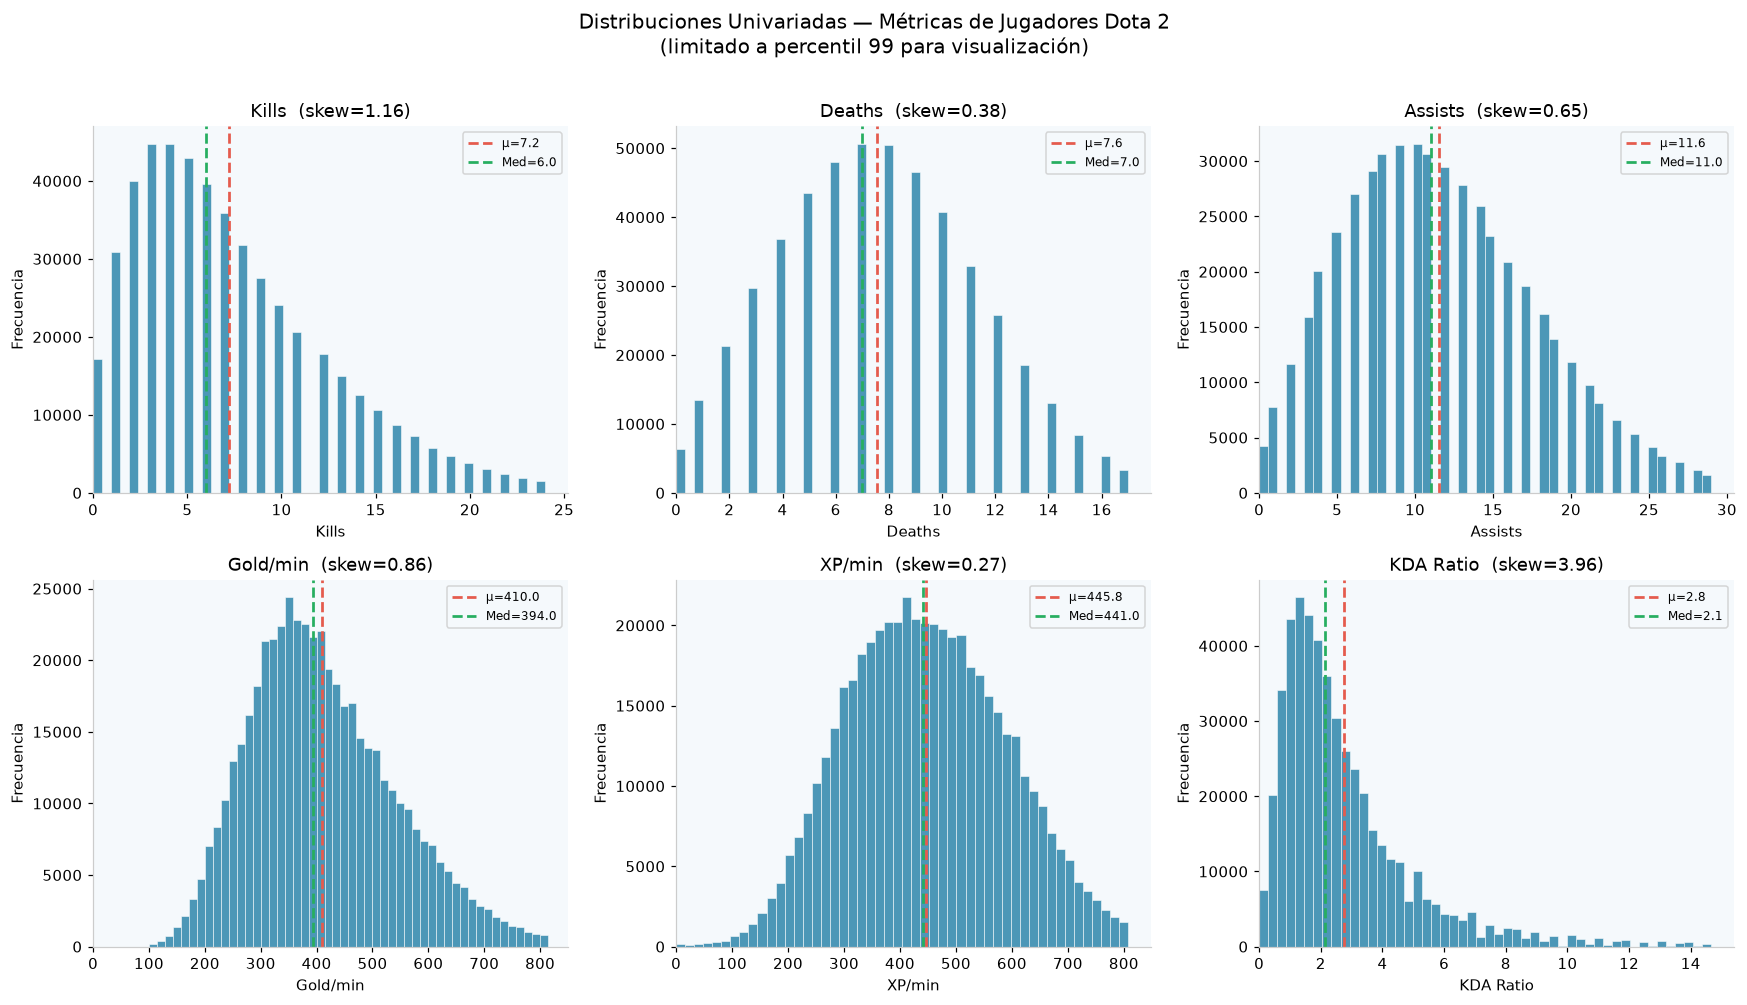


📌 PREGUNTAS PARA REFLEXIONAR:
  1. ¿Qué variables tienen distribución más simétrica? ¿Cuáles son más sesgadas?
  2. ¿Por qué hero_healing probablemente tiene skewness muy alto?
     (Pista: la mayoría de héroes no cura nada — solo los supports)
  3. ¿La distribución de kills parece normal o sesgada positivamente?


In [27]:
# ── Celda 5.2: Distribuciones de métricas clave ───────────────────────────
cols_viz = ['kills', 'deaths', 'assists', 'gold_per_min', 'xp_per_min', 'kda_ratio']
labels   = ['Kills', 'Deaths', 'Assists', 'Gold/min', 'XP/min', 'KDA Ratio']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, (col, label) in enumerate(zip(cols_viz, labels)):
    data = df[col].dropna()
    # Limitar outliers extremos para visualización (percentil 99)
    p99 = data.quantile(0.99)
    data_viz = data[data <= p99]

    axes[i].hist(data_viz, bins=50, color=COLORS['steel'],
                 edgecolor='white', alpha=0.85, linewidth=0.4)
    axes[i].axvline(data_viz.mean(), color=COLORS['coral'],
                    linestyle='--', linewidth=1.8, label=f'μ={data_viz.mean():.1f}')
    axes[i].axvline(data_viz.median(), color=COLORS['green'],
                    linestyle='--', linewidth=1.8, label=f'Med={data_viz.median():.1f}')
    axes[i].set_title(f'{label}  (skew={data.skew():.2f})')
    axes[i].set_xlabel(label)
    axes[i].set_ylabel('Frecuencia')
    axes[i].legend(fontsize=8)
    axes[i].set_xlim(left=0)

fig.suptitle('Distribuciones Univariadas — Métricas de Jugadores Dota 2\n(limitado a percentil 99 para visualización)',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print()
print("📌 PREGUNTAS PARA REFLEXIONAR:")
print("  1. ¿Qué variables tienen distribución más simétrica? ¿Cuáles son más sesgadas?")
print("  2. ¿Por qué hero_healing probablemente tiene skewness muy alto?")
print("     (Pista: la mayoría de héroes no cura nada — solo los supports)")
print("  3. ¿La distribución de kills parece normal o sesgada positivamente?")

---
## ⚔️ Sección 6 — Análisis por Resultado (Ganadores vs. Perdedores)

### Niveles de análisis en esta sección:
1. **Asociación descriptiva**: comparar promedios entre grupos
2. **Tamaño del efecto**: cuantificar si la diferencia es relevante (Cohen's d)
3. **Mediana vs. Media**: evaluar si los promedios son representativos

> **⚠️ Recordatorio crítico:** Encontrar que ganadores tienen más oro NO significa que el oro **cause** la victoria. El oro final puede ser **consecuencia** de ir ganando. Para pensar causalmente, necesitaríamos datos de oro al minuto 10, no el total acumulado.

In [28]:
# ── Celda 6.1: Promedios por resultado — asociación descriptiva ──────────
print("COMPARACIÓN DE MÉTRICAS: GANADORES vs. PERDEDORES")
print("=" * 60)
print("Nivel de análisis: ASOCIACIÓN DESCRIPTIVA (no es causalidad)")
print()

cols_comp = ['kills', 'deaths', 'assists', 'gold_per_min',
             'xp_per_min', 'hero_damage', 'tower_damage', 'kda_ratio']

comp_mean   = df.groupby('resultado')[cols_comp].mean().T.round(3)
comp_median = df.groupby('resultado')[cols_comp].median().T.round(3)
comp_std    = df.groupby('resultado')[cols_comp].std().T.round(3)

comp_mean.columns = ['Perdedores (μ)', 'Ganadores (μ)']
comp_mean['Diferencia'] = (comp_mean['Ganadores (μ)'] - comp_mean['Perdedores (μ)']).round(3)
comp_mean['Dif. relativa %'] = ((comp_mean['Diferencia'] / comp_mean['Perdedores (μ)'].abs()) * 100).round(1)

display(comp_mean)

COMPARACIÓN DE MÉTRICAS: GANADORES vs. PERDEDORES
Nivel de análisis: ASOCIACIÓN DESCRIPTIVA (no es causalidad)



,Perdedores (μ),Ganadores (μ),Diferencia,Dif. relativa %
kills,5.872,8.936,3.064,52.200
deaths,9.204,6.156,-3.048,-33.100
assists,9.435,14.088,4.653,49.300
gold_per_min,349.169,481.025,131.856,37.800
xp_per_min,395.629,504.329,108.700,27.500
hero_damage,10850.280,13618.218,2767.938,25.500
tower_damage,450.889,2175.487,1724.598,382.500
kda_ratio,1.609,4.259,2.650,164.700


In [29]:
# ── Celda 6.2: Tamaño del efecto — Cohen's d ─────────────────────────────
#
# Cohen's d estandariza la diferencia de medias usando la desviación combinada.
# Se usa cuando comparamos una variable numérica entre dos grupos independientes.

print("TAMAÑO DEL EFECTO — Cohen's d")
print("=" * 55)
print("Uso: comparar una métrica numérica entre dos grupos, por ejemplo GPM de ganadores y perdedores.")
print("Magnitud de |d|: <0.2 trivial | 0.2–<0.5 pequeña | 0.5–<0.8 media | ≥0.8 grande")
print("Signo: d>0 favorece al primer grupo; d<0 favorece al segundo.")
print()

def cohen_d(grupo1, grupo2):
    """Cohen's d para dos grupos usando la desviación estándar combinada."""
    grupo1 = pd.Series(grupo1).dropna().astype(float)
    grupo2 = pd.Series(grupo2).dropna().astype(float)
    n1, n2 = len(grupo1), len(grupo2)
    if n1 < 2 or n2 < 2:
        return np.nan
    pooled_var = (((n1 - 1) * grupo1.var(ddof=1)) + ((n2 - 1) * grupo2.var(ddof=1))) / (n1 + n2 - 2)
    pooled_std = np.sqrt(pooled_var)
    return np.nan if pooled_std == 0 else (grupo1.mean() - grupo2.mean()) / pooled_std


def magnitud_cohen(d):
    """Etiqueta pedagógica basada en el valor absoluto del efecto."""
    valor = abs(d)
    return ('Grande' if valor >= 0.8 else 'Medio' if valor >= 0.5 else
            'Pequeño' if valor >= 0.2 else 'Trivial')

win_df  = df[df['resultado'] == 'win']
lose_df = df[df['resultado'] == 'lose']

efecto_df = []
for col in cols_comp:
    d = cohen_d(win_df[col].dropna(), lose_df[col].dropna())
    magnitud = magnitud_cohen(d)
    efecto_df.append({'Variable': col, "Cohen's d": round(d, 3), 'Magnitud': magnitud})

efecto_result = pd.DataFrame(efecto_df).set_index('Variable')
efecto_result = efecto_result.reindex(efecto_result["Cohen's d"].abs().sort_values(ascending=False).index)
display(efecto_result)

print()
print("📌 EJEMPLO GUIADO — gold_per_min")
d_gpm_ejemplo = cohen_d(win_df['gold_per_min'], lose_df['gold_per_min'])
print(f"  Media ganadores  : {win_df['gold_per_min'].mean():.1f} GPM")
print(f"  Media perdedores : {lose_df['gold_per_min'].mean():.1f} GPM")
print(f"  Cohen's d        : {d_gpm_ejemplo:.3f} ({magnitud_cohen(d_gpm_ejemplo).lower()})")
print("  Lectura: la distancia entre medias se expresa en desviaciones estándar combinadas.")
print("  El signo positivo indica mayor GPM en ganadores porque fueron el primer grupo.")
print()
print("⚠️ LÍMITES DE LA INTERPRETACIÓN")
print("  • Cohen's d cuantifica magnitud; no demuestra causalidad ni significancia estadística.")
print("  • Los puntos de corte son guías, no leyes universales: importa el contexto del juego.")
print("  • Los 10 jugadores de una partida están relacionados; aquí d es descriptivo.")
print("  • Conviene revisar distribuciones, outliers y tamaños de grupo antes de concluir.")

TAMAÑO DEL EFECTO — Cohen's d
Uso: comparar una métrica numérica entre dos grupos, por ejemplo GPM de ganadores y perdedores.
Magnitud de |d|: <0.2 trivial | 0.2–<0.5 pequeña | 0.5–<0.8 media | ≥0.8 grande
Signo: d>0 favorece al primer grupo; d<0 favorece al segundo.



,Cohen's d,Magnitud
Variable,,
tower_damage,1.091,Grande
gold_per_min,1.085,Grande
kda_ratio,1.042,Grande
deaths,-0.874,Grande
xp_per_min,0.800,Medio
assists,0.781,Medio
kills,0.587,Medio
hero_damage,0.421,Pequeño



📌 EJEMPLO GUIADO — gold_per_min
  Media ganadores  : 481.0 GPM
  Media perdedores : 349.2 GPM
  Cohen's d        : 1.085 (grande)
  Lectura: la distancia entre medias se expresa en desviaciones estándar combinadas.
  El signo positivo indica mayor GPM en ganadores porque fueron el primer grupo.

⚠️ LÍMITES DE LA INTERPRETACIÓN
  • Cohen's d cuantifica magnitud; no demuestra causalidad ni significancia estadística.
  • Los puntos de corte son guías, no leyes universales: importa el contexto del juego.
  • Los 10 jugadores de una partida están relacionados; aquí d es descriptivo.
  • Conviene revisar distribuciones, outliers y tamaños de grupo antes de concluir.


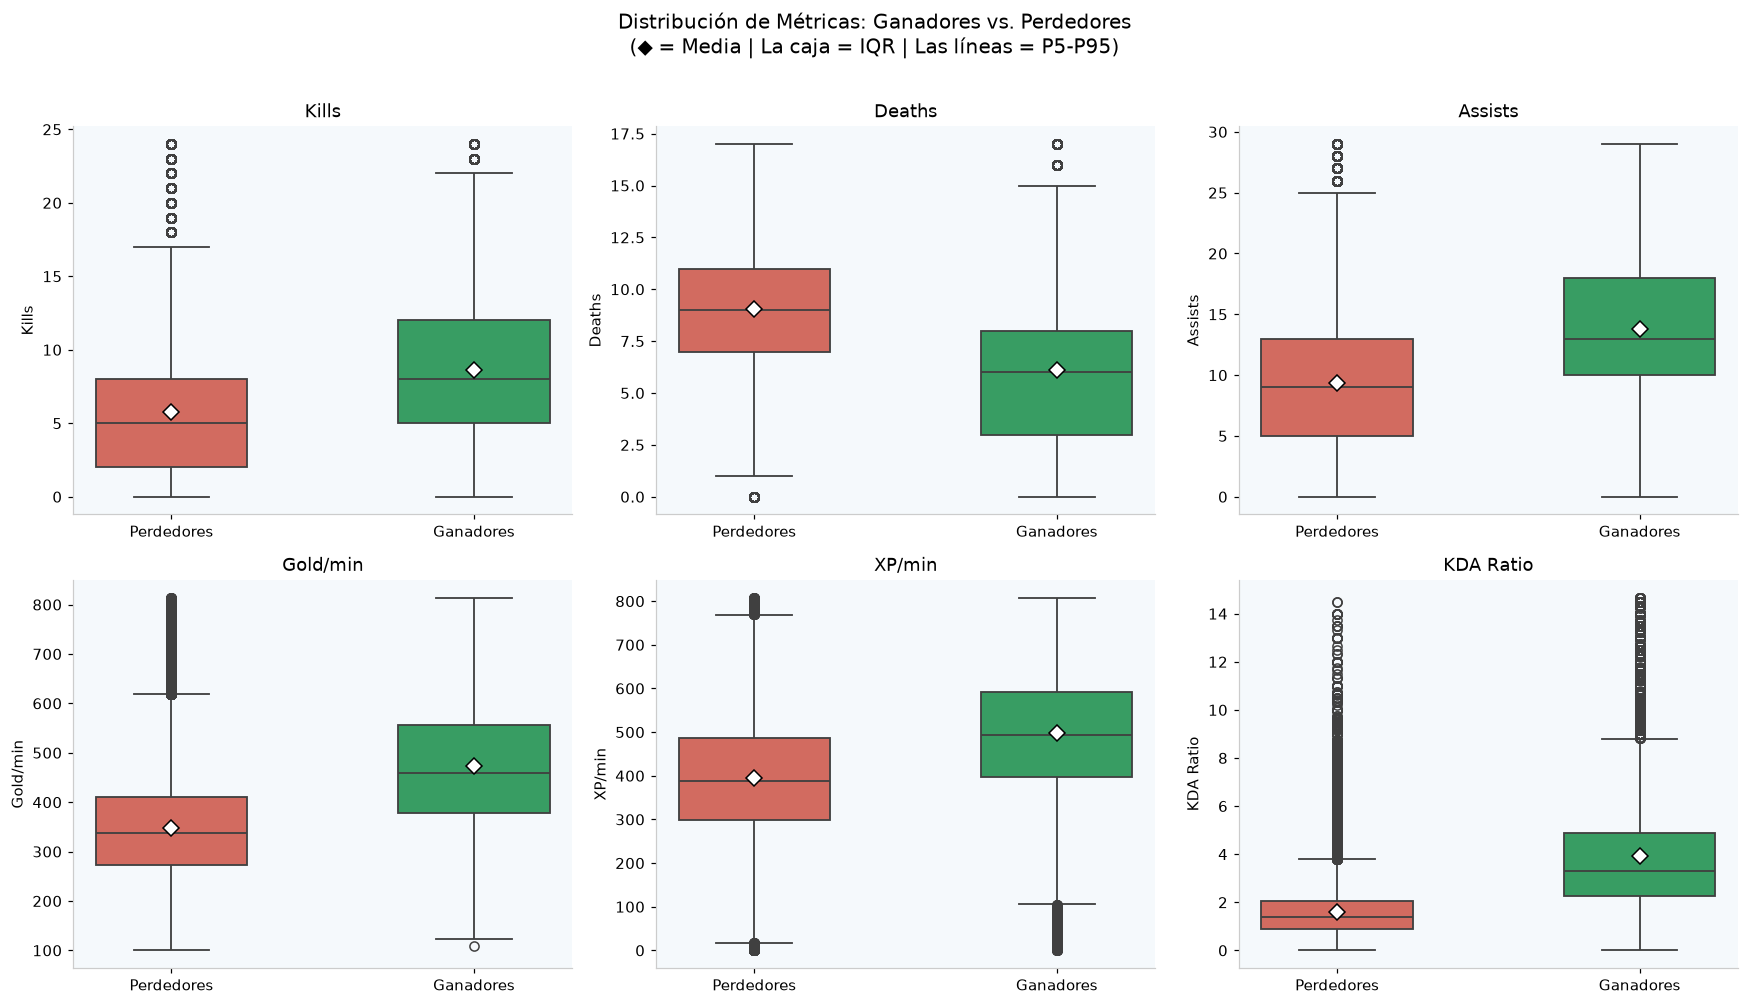


📌 PREGUNTAS PARA REFLEXIONAR:
  1. ¿En qué métrica es mayor la diferencia entre grupos?
  2. ¿Hay mucho solapamiento entre las distribuciones?
     (si se solapan mucho, la diferencia es difícil de usar para predecir)
  3. deaths es MAYOR en perdedores — ¿Esto causa la derrota o es consecuencia?


In [30]:
# ── Celda 6.3: Visualización — Boxplots comparativos ─────────────────────
cols_box = ['kills', 'deaths', 'assists', 'gold_per_min', 'xp_per_min', 'kda_ratio']
labels_box = ['Kills', 'Deaths', 'Assists', 'Gold/min', 'XP/min', 'KDA Ratio']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

palette = {'win': COLORS['green'], 'lose': COLORS['coral']}

for i, (col, label) in enumerate(zip(cols_box, labels_box)):
    # Limitar a P99 para visualización
    p99 = df[col].quantile(0.99)
    df_viz = df[df[col] <= p99]

    sns.boxplot(data=df_viz, x='resultado', y=col,
                palette=palette, ax=axes[i],
                order=['lose', 'win'],
                width=0.5, linewidth=1.2)
    axes[i].set_title(f'{label}')
    axes[i].set_xlabel('')
    axes[i].set_xticklabels(['Perdedores', 'Ganadores'])
    axes[i].set_ylabel(label)

    # Añadir medias como puntos
    for j, res in enumerate(['lose', 'win']):
        media = df_viz[df_viz['resultado']==res][col].mean()
        axes[i].plot(j, media, 'D', color='white',
                     markersize=7, markeredgecolor='black', zorder=5, label='Media' if j==0 else '')

fig.suptitle('Distribución de Métricas: Ganadores vs. Perdedores\n(◆ = Media | La caja = IQR | Las líneas = P5-P95)',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print()
print("📌 PREGUNTAS PARA REFLEXIONAR:")
print("  1. ¿En qué métrica es mayor la diferencia entre grupos?")
print("  2. ¿Hay mucho solapamiento entre las distribuciones?")
print("     (si se solapan mucho, la diferencia es difícil de usar para predecir)")
print("  3. deaths es MAYOR en perdedores — ¿Esto causa la derrota o es consecuencia?")

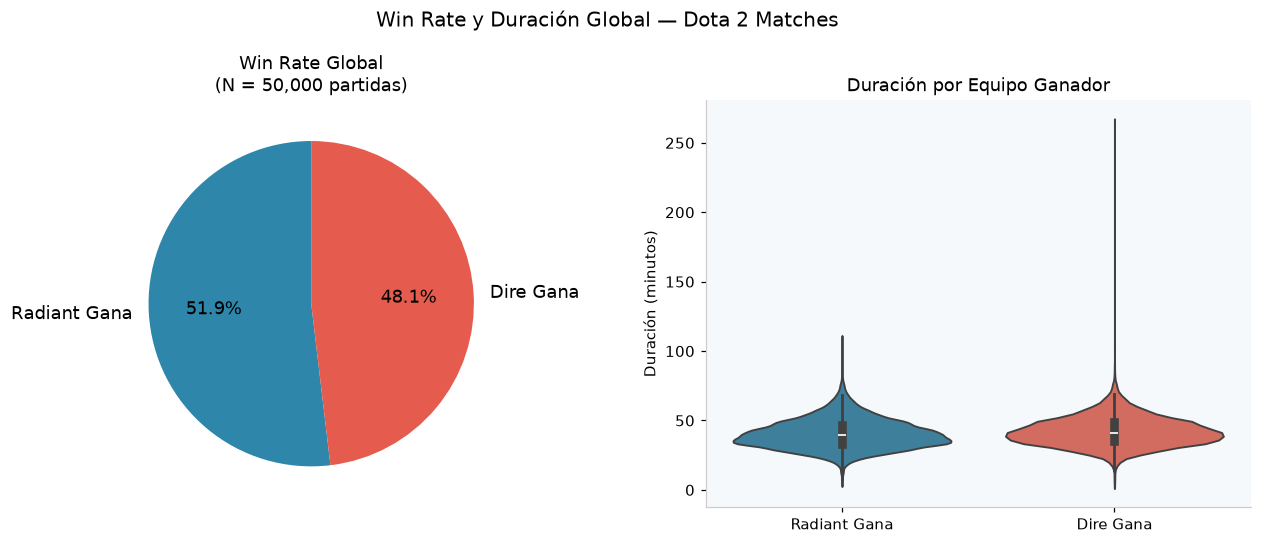


📌 Radiant gana en el 51.9% de las partidas.
   Esto puede deberse a una ligera ventaja de diseño del mapa para Radiant.
   → Sesgo de diseño del juego: no confundir con habilidad del jugador.


In [31]:
# ── Celda 6.4: Win Rate global Radiant vs Dire ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Win rate global
wr_counts = matches['radiant_win'].value_counts()
axes[0].pie(
    wr_counts.values,
    labels=['Radiant Gana', 'Dire Gana'],
    colors=[COLORS['steel'], COLORS['coral']],
    autopct='%1.1f%%', startangle=90,
    textprops={'fontsize': 12}
)
axes[0].set_title(f'Win Rate Global\n(N = {len(matches):,} partidas)')

# Duración según resultado de equipo
matches['resultado_match'] = matches['radiant_win'].map({True: 'Radiant Gana', False: 'Dire Gana'})
matches['dur_min'] = matches['duration'] / 60
sns.violinplot(data=matches, x='resultado_match', y='dur_min',
               palette={'Radiant Gana': COLORS['steel'], 'Dire Gana': COLORS['coral']},
               ax=axes[1], cut=0)
axes[1].set_title('Duración por Equipo Ganador')
axes[1].set_xlabel('')
axes[1].set_ylabel('Duración (minutos)')

plt.suptitle('Win Rate y Duración Global — Dota 2 Matches', fontsize=13)
plt.tight_layout()
plt.show()

print()
print(f"📌 Radiant gana en el {matches['radiant_win'].mean()*100:.1f}% de las partidas.")
print("   Esto puede deberse a una ligera ventaja de diseño del mapa para Radiant.")
print("   → Sesgo de diseño del juego: no confundir con habilidad del jugador.")

---
## 🦸 Sección 7 — Análisis por Héroe — Control del Sesgo de Popularidad

### El sesgo de popularidad en Dota 2
Un héroe puede tener muchas victorias absolutas simplemente porque **se juega mucho más** que otros. Para comparar héroes justamente necesitamos **proporciones (win rate)**, no conteos absolutos.

### El sesgo por muestra pequeña
Un héroe con 85% de win rate en 4 partidas no es evidencia sólida. Necesitamos un **mínimo de partidas** para que el win rate sea estadísticamente confiable.

**Regla práctica:** Filtrar héroes con al menos **30 partidas** antes de interpretar su win rate.

TOP 15 HÉROES MÁS JUGADOS (conteos absolutos)


,Partidas,count
0,Windranger,20881
1,Shadow Fiend,17007
2,Invoker,11675
3,Earthshaker,11323
4,Slardar,11181
5,Queen of Pain,10590
6,Juggernaut,10394
7,Tusk,10305
8,Alchemist,9823
9,Pudge,9447


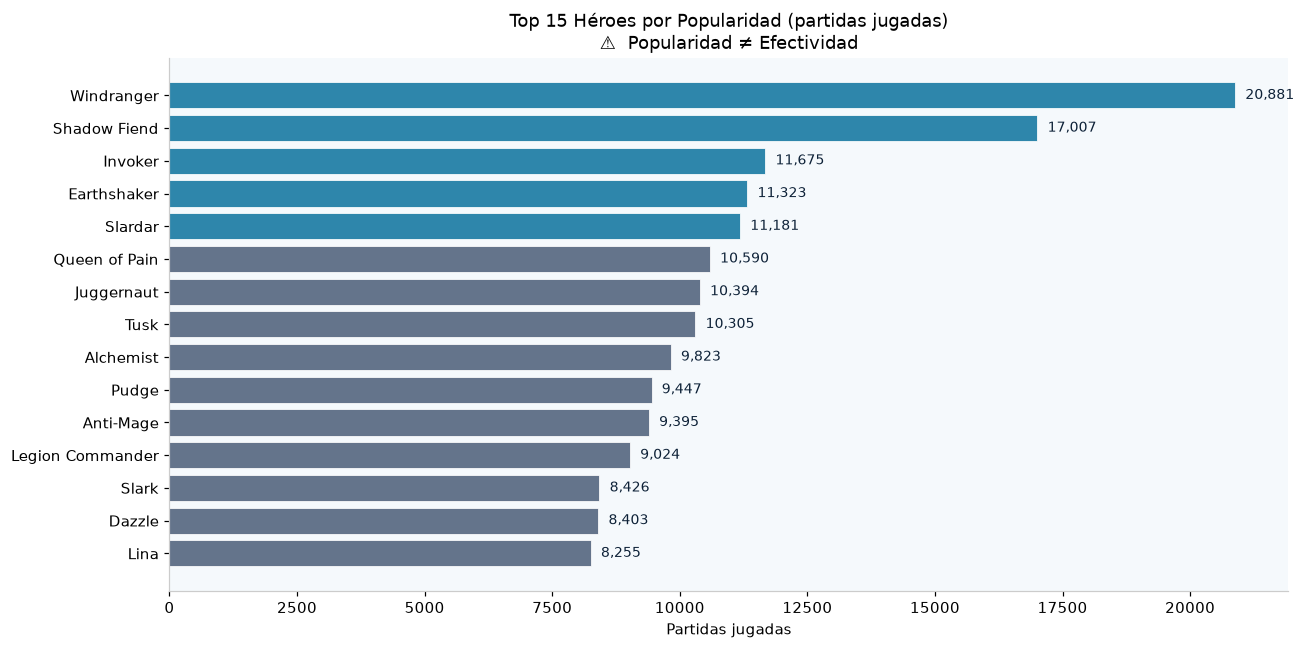


📌 SESGO DE POPULARIDAD:
   El héroe más popular puede ganar más partidas solo por volumen de uso.
   → Siempre analizar WIN RATE, no victorias absolutas.


In [32]:
# ── Celda 7.1: Popularidad de héroes — conteos absolutos ─────────────────
print("TOP 15 HÉROES MÁS JUGADOS (conteos absolutos)")
print("=" * 50)

hero_counts = df['localized_name'].value_counts().head(15)
display(hero_counts.reset_index().rename(columns={'index':'Héroe','localized_name':'Partidas'}))

fig, ax = plt.subplots(figsize=(12, 6))
colors_bar = [COLORS['steel'] if i < 5 else COLORS['gray'] for i in range(15)]
ax.barh(hero_counts.index[::-1], hero_counts.values[::-1],
        color=colors_bar[::-1], edgecolor='white', linewidth=0.5)
ax.set_xlabel('Partidas jugadas')
ax.set_title('Top 15 Héroes por Popularidad (partidas jugadas)\n⚠️  Popularidad ≠ Efectividad')
for i, v in enumerate(hero_counts.values[::-1]):
    ax.text(v + 200, i, f'{v:,}', va='center', fontsize=9, color=COLORS['navy'])
plt.tight_layout()
plt.show()

print()
print("📌 SESGO DE POPULARIDAD:")
print("   El héroe más popular puede ganar más partidas solo por volumen de uso.")
print("   → Siempre analizar WIN RATE, no victorias absolutas.")

In [33]:
# ── Celda 7.2: Win rate por héroe — sin y con filtro de muestra mínima ───
print("WIN RATE POR HÉROE — comparando con y sin filtro de muestra mínima")
print("=" * 65)

hero_stats = df.groupby('localized_name').agg(
    partidas   = ('match_id',      'count'),
    win_rate   = ('gano',          'mean'),
    avg_kills  = ('kills',         'mean'),
    avg_deaths = ('deaths',        'mean'),
    avg_assists= ('assists',       'mean'),
    avg_gpm    = ('gold_per_min',  'mean'),
    avg_kda    = ('kda_ratio',     'mean'),
).round(3)

# SIN filtro — puede incluir héroes con muy pocas partidas
print("Top 10 win rate SIN filtro (⚠️  potencialmente sesgado):")
display(hero_stats.sort_values('win_rate', ascending=False).head(10))

# CON filtro mínimo de 30 partidas
MUESTRA_MINIMA = 30
hero_filtrado = hero_stats[hero_stats['partidas'] >= MUESTRA_MINIMA]

print(f"\nHéroes excluidos por muestra < {MUESTRA_MINIMA} partidas: "
      f"{len(hero_stats) - len(hero_filtrado)} de {len(hero_stats)} héroes")
print()
print(f"Top 10 win rate CON filtro (mínimo {MUESTRA_MINIMA} partidas — más confiable):")
display(hero_filtrado.sort_values('win_rate', ascending=False).head(10))

WIN RATE POR HÉROE — comparando con y sin filtro de muestra mínima
Top 10 win rate SIN filtro (⚠️  potencialmente sesgado):


,partidas,win_rate,avg_kills,avg_deaths,avg_assists,avg_gpm,avg_kda
localized_name,,,,,,,
Omniknight,5160,0.591,3.091,6.684,8.923,312.309,2.143
Spectre,6660,0.583,9.657,6.455,16.877,495.295,4.652
Wraith King,7794,0.580,7.866,5.666,11.855,479.170,4.183
Undying,5951,0.569,5.900,7.966,17.611,348.256,3.389
Abaddon,3310,0.569,5.006,6.279,12.647,363.055,3.134
Ursa,4302,0.568,11.712,7.086,8.605,474.532,3.492
Necrophos,5969,0.564,8.766,7.996,15.271,405.255,3.521
Lich,4687,0.560,5.602,7.397,12.551,318.566,2.877
Slardar,11181,0.559,6.122,7.579,12.655,383.120,2.846



Héroes excluidos por muestra < 30 partidas: 0 de 110 héroes

Top 10 win rate CON filtro (mínimo 30 partidas — más confiable):


,partidas,win_rate,avg_kills,avg_deaths,avg_assists,avg_gpm,avg_kda
localized_name,,,,,,,
Omniknight,5160,0.591,3.091,6.684,8.923,312.309,2.143
Spectre,6660,0.583,9.657,6.455,16.877,495.295,4.652
Wraith King,7794,0.580,7.866,5.666,11.855,479.170,4.183
Undying,5951,0.569,5.900,7.966,17.611,348.256,3.389
Abaddon,3310,0.569,5.006,6.279,12.647,363.055,3.134
Ursa,4302,0.568,11.712,7.086,8.605,474.532,3.492
Necrophos,5969,0.564,8.766,7.996,15.271,405.255,3.521
Lich,4687,0.560,5.602,7.397,12.551,318.566,2.877
Slardar,11181,0.559,6.122,7.579,12.655,383.120,2.846


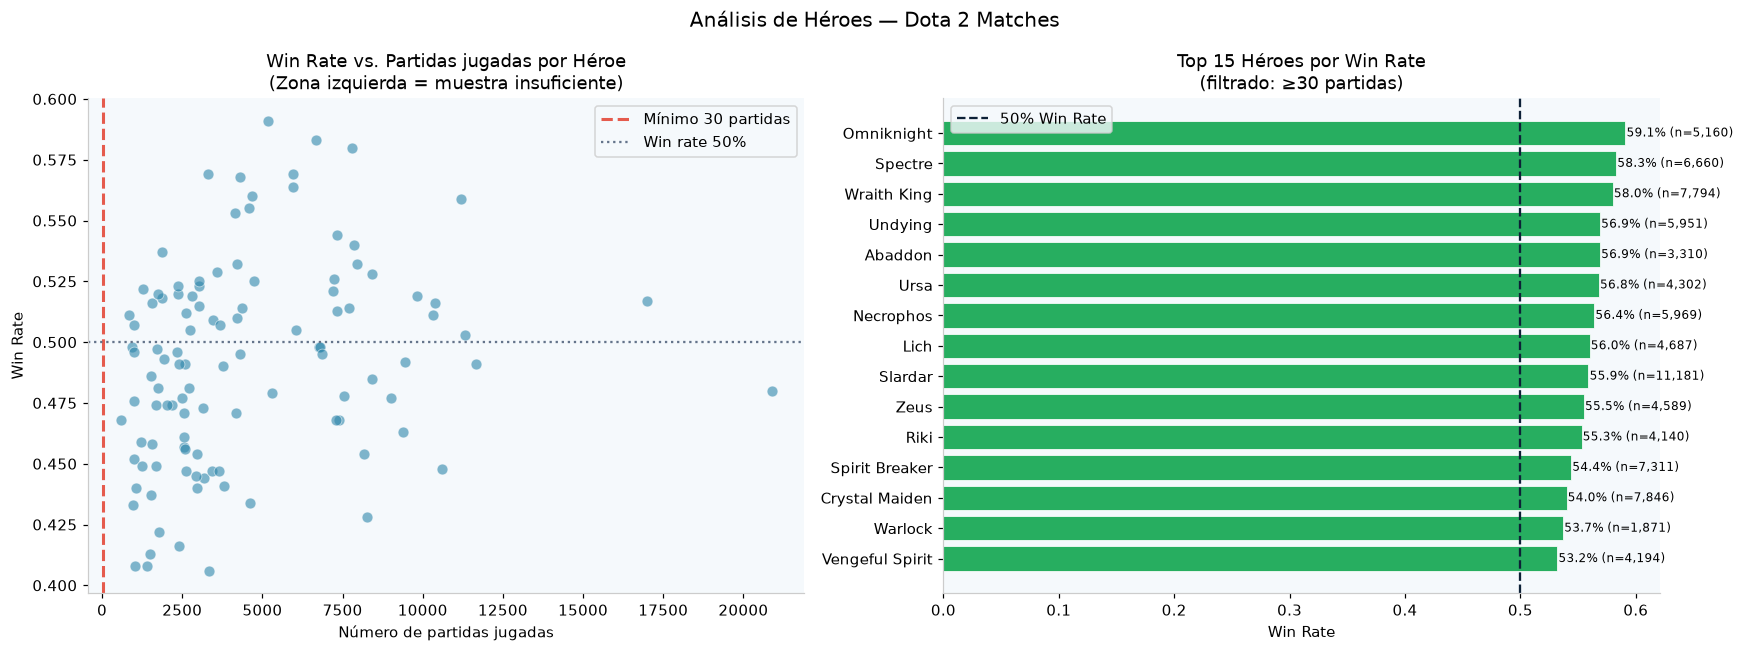


📌 OBSERVACIONES:
  • Los héroes con muy pocas partidas (izquierda del scatter) tienen win rates extremos.
  • Después del filtro, los win rates se concentran más cerca del 50%.
  • Un héroe con win rate muy alto puede estar en un 'meta' favorable (patch específico).


In [34]:
# ── Celda 7.3: Visualización win rate vs. partidas ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter: win rate vs. número de partidas
axes[0].scatter(hero_stats['partidas'], hero_stats['win_rate'],
                alpha=0.6, color=COLORS['steel'], s=50, edgecolors='white', linewidth=0.5)
axes[0].axvline(MUESTRA_MINIMA, color=COLORS['coral'], linestyle='--', linewidth=2,
                label=f'Mínimo {MUESTRA_MINIMA} partidas')
axes[0].axhline(0.5, color=COLORS['gray'], linestyle=':', linewidth=1.5, label='Win rate 50%')
axes[0].set_xlabel('Número de partidas jugadas')
axes[0].set_ylabel('Win Rate')
axes[0].set_title('Win Rate vs. Partidas jugadas por Héroe\n(Zona izquierda = muestra insuficiente)')
axes[0].legend()

# Top 15 héroes filtrados por win rate
top15 = hero_filtrado.sort_values('win_rate', ascending=False).head(15)
colors_wr = [COLORS['green'] if wr > 0.52 else COLORS['coral'] if wr < 0.48
             else COLORS['steel'] for wr in top15['win_rate']]
axes[1].barh(top15.index[::-1], top15['win_rate'][::-1],
             color=colors_wr[::-1], edgecolor='white', linewidth=0.5)
axes[1].axvline(0.5, color=COLORS['navy'], linestyle='--', linewidth=1.5, label='50% Win Rate')
axes[1].set_xlabel('Win Rate')
axes[1].set_title(f'Top 15 Héroes por Win Rate\n(filtrado: ≥{MUESTRA_MINIMA} partidas)')
for i, (wr, n) in enumerate(zip(top15['win_rate'][::-1], top15['partidas'][::-1])):
    axes[1].text(wr + 0.001, i, f'{wr:.1%} (n={n:,})', va='center', fontsize=8)
axes[1].legend()

plt.suptitle('Análisis de Héroes — Dota 2 Matches', fontsize=13)
plt.tight_layout()
plt.show()

print()
print("📌 OBSERVACIONES:")
print("  • Los héroes con muy pocas partidas (izquierda del scatter) tienen win rates extremos.")
print("  • Después del filtro, los win rates se concentran más cerca del 50%.")
print("  • Un héroe con win rate muy alto puede estar en un 'meta' favorable (patch específico).")

---
## 🎭 Sección 8 — Análisis por Posición/Rol — Paradoja de Simpson

### La Paradoja de Simpson aplicada a Dota 2
Si calculamos el promedio de kills **mezclando todas las posiciones**, obtenemos un número que puede ser **engañoso**:
- Un Slot 0 (aprox. carry) promedia ~8-10 kills por partida
- Un Hard Support (Pos 4) promedia ~1-2 kills por partida

Si comparamos el kill promedio global de ganadores vs. perdedores **sin segmentar por posición**, la diferencia puede reflejar simplemente que los equipos ganadores tienen sus carries rindiendo mejor — no que kills en general cause la victoria.

> **Regla:** Si el fenómeno tiene subgrupos importantes (posiciones, roles, tipos de partida), **no analices todo junto**.

In [35]:
# ── Celda 8.1: Desempeño promedio por posición ───────────────────────────
print("ANÁLISIS POR POSICIÓN — kills, gold_per_min, kda_ratio")
print("=" * 60)

pos_stats = df.groupby('pos_nombre').agg(
    partidas   = ('match_id',     'count'),
    win_rate   = ('gano',         'mean'),
    avg_kills  = ('kills',        'mean'),
    avg_deaths = ('deaths',       'mean'),
    avg_assists= ('assists',      'mean'),
    avg_gpm    = ('gold_per_min', 'mean'),
    avg_kda    = ('kda_ratio',    'mean'),
).round(3)

# Reordenar por posición
orden_pos = ['Slot 0 (aprox. carry)', 'Slot 1 (aprox. mid)', 'Slot 2 (aprox. offlane)',
             'Slot 3 (aprox. support)', 'Slot 4 (aprox. support)']
pos_stats = pos_stats.reindex([p for p in orden_pos if p in pos_stats.index])

display(pos_stats)

print()
print("📌 PARADOJA DE SIMPSON — DEMOSTRACIÓN:")
print(f"  Kills promedio GLOBAL mezclado: {df['kills'].mean():.2f}")
print("  Kills promedio por posición:")
for pos in orden_pos:
    if pos in pos_stats.index:
        k = pos_stats.loc[pos, 'avg_kills']
        print(f"    {pos:<22} {k:.2f}")
print()
print("  → El promedio global (mezclado) NO representa a ninguna posición individual.")
print("  → Comparar kills entre posiciones distintas es injusto.")

ANÁLISIS POR POSICIÓN — kills, gold_per_min, kda_ratio


,partidas,win_rate,avg_kills,avg_deaths,avg_assists,avg_gpm,avg_kda
pos_nombre,,,,,,,
Slot 0 (aprox. carry),99998,0.500,7.600,7.653,11.735,420.783,2.965
Slot 1 (aprox. mid),99998,0.500,7.375,7.678,11.779,413.807,2.926
Slot 2 (aprox. offlane),99998,0.500,7.391,7.693,11.796,414.736,2.939
Slot 3 (aprox. support),99998,0.500,7.401,7.688,11.774,414.703,2.932
Slot 4 (aprox. support),99998,0.500,7.253,7.689,11.724,411.457,2.905



📌 PARADOJA DE SIMPSON — DEMOSTRACIÓN:
  Kills promedio GLOBAL mezclado: 7.40
  Kills promedio por posición:
    Slot 0 (aprox. carry)  7.60
    Slot 1 (aprox. mid)    7.38
    Slot 2 (aprox. offlane) 7.39
    Slot 3 (aprox. support) 7.40
    Slot 4 (aprox. support) 7.25

  → El promedio global (mezclado) NO representa a ninguna posición individual.
  → Comparar kills entre posiciones distintas es injusto.


KILLS PROMEDIO: Ganadores vs. Perdedores — por posición


,Perdedores,Ganadores,Diferencia,Dif. %
pos_nombre,,,,
Slot 0 (aprox. carry),6.008,9.193,3.180,52.900
Slot 1 (aprox. mid),5.846,8.905,3.060,52.300
Slot 2 (aprox. offlane),5.857,8.924,3.070,52.400
Slot 3 (aprox. support),5.867,8.934,3.070,52.300
Slot 4 (aprox. support),5.782,8.724,2.940,50.800



📌 INTERPRETACIÓN:
  • La diferencia de kills entre ganadores y perdedores VARÍA por posición.
  • En Carry y Mid la diferencia es grande (posiciones ofensivas).
  • En Hard Support la diferencia es pequeña (su rol es otro — curar, visión).
  → NO es justo evaluar supports y carries con la misma métrica de kills.


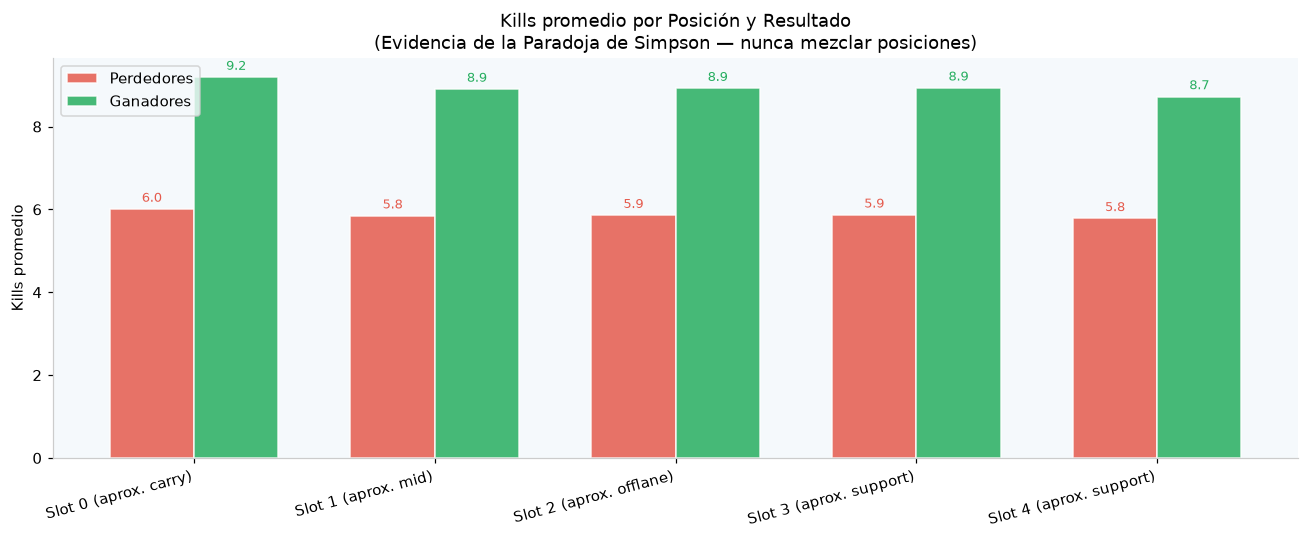

In [36]:
# ── Celda 8.2: Kills ganadores vs. perdedores por posición ────────────────
print("KILLS PROMEDIO: Ganadores vs. Perdedores — por posición")
print("=" * 62)

pivot = df.groupby(['pos_nombre', 'resultado'])['kills'].mean().unstack()
pivot = pivot.reindex([p for p in orden_pos if p in pivot.index])
pivot.columns = ['Perdedores', 'Ganadores']
pivot['Diferencia'] = (pivot['Ganadores'] - pivot['Perdedores']).round(2)
pivot['Dif. %'] = ((pivot['Diferencia'] / pivot['Perdedores']) * 100).round(1)
display(pivot.round(3))

print()
print("📌 INTERPRETACIÓN:")
print("  • La diferencia de kills entre ganadores y perdedores VARÍA por posición.")
print("  • En Carry y Mid la diferencia es grande (posiciones ofensivas).")
print("  • En Hard Support la diferencia es pequeña (su rol es otro — curar, visión).")
print("  → NO es justo evaluar supports y carries con la misma métrica de kills.")

# Visualización
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(pivot))
width = 0.35
bars1 = ax.bar(x - width/2, pivot['Perdedores'], width, label='Perdedores',
               color=COLORS['coral'], alpha=0.85, edgecolor='white')
bars2 = ax.bar(x + width/2, pivot['Ganadores'], width, label='Ganadores',
               color=COLORS['green'], alpha=0.85, edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(pivot.index, rotation=15, ha='right')
ax.set_ylabel('Kills promedio')
ax.set_title('Kills promedio por Posición y Resultado\n(Evidencia de la Paradoja de Simpson — nunca mezclar posiciones)')
ax.legend()

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8.5, color=COLORS['coral'])
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8.5, color=COLORS['green'])
plt.tight_layout()
plt.show()

---
## 🔗 Sección 9 — Correlaciones — Pearson y Spearman

### ¿Qué mide la correlación?
- **Pearson (r):** mide relación *lineal* entre dos variables numéricas. Rango: [-1, 1].
- **Spearman (ρ):** mide relación *monótona* (no necesariamente lineal). Más robusta ante outliers.

### Regla de interpretación (Cohen, 1988)
| |r| | Interpretación |
|------|----------------|
| 0.00 – 0.10 | Negligible |
| 0.10 – 0.30 | Pequeña |
| 0.30 – 0.50 | Moderada |
| 0.50 – 0.70 | Grande |
| > 0.70 | Muy grande |

> **⚠️ Correlación ≠ Causalidad.** Una correlación r=0.82 entre gold_per_min y xp_per_min no significa que el oro *cause* la experiencia. Ambas pueden ser consecuencia de un tercer factor (habilidad del jugador, posición en el mapa, duración de la partida).

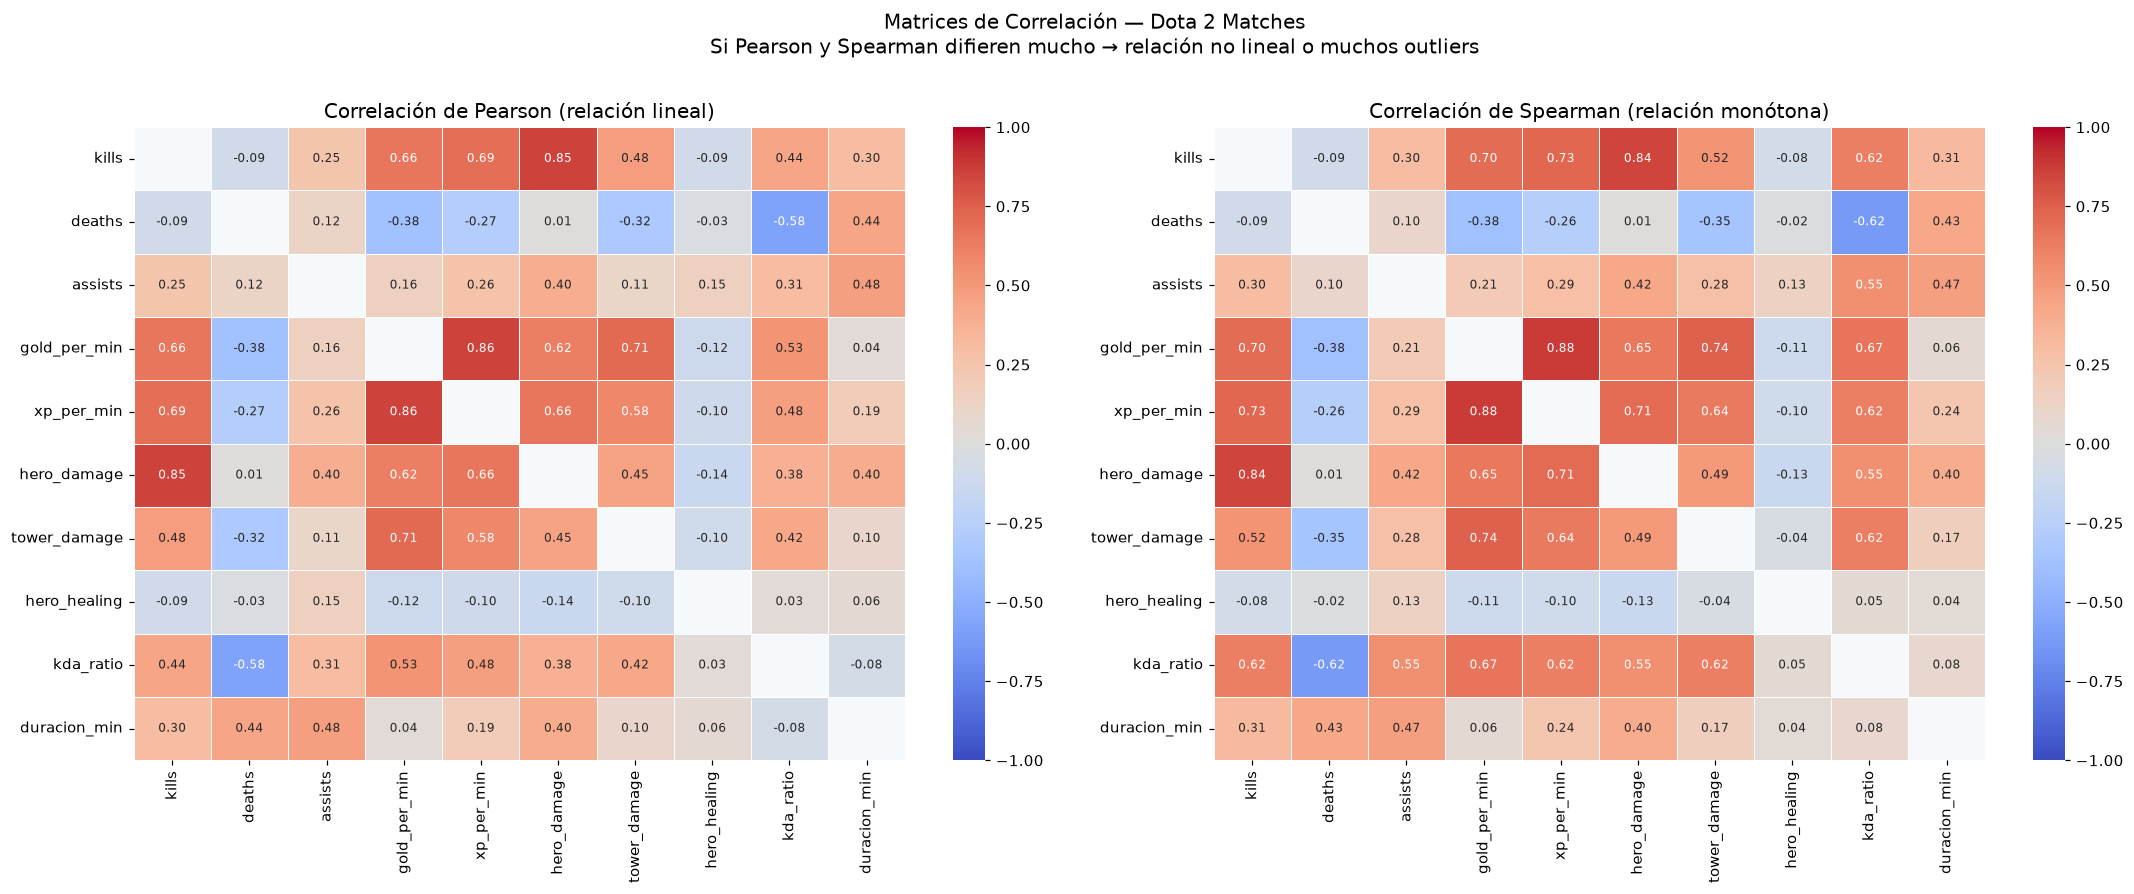


📌 CORRELACIONES DESTACADAS (interpretar con cautela):


,Variable 1,Variable 2,Pearson r,Spearman ρ
24,gold_per_min,xp_per_min,0.859,0.879
4,kills,hero_damage,0.854,0.844
26,gold_per_min,tower_damage,0.712,0.743
3,kills,xp_per_min,0.690,0.726
30,xp_per_min,hero_damage,0.663,0.711
2,kills,gold_per_min,0.659,0.702
25,gold_per_min,hero_damage,0.620,0.653
31,xp_per_min,tower_damage,0.582,0.641
15,deaths,kda_ratio,-0.577,-0.624
28,gold_per_min,kda_ratio,0.530,0.668


In [37]:
# ── Celda 9.1: Matrices de correlación Pearson y Spearman ────────────────
metricas_corr = ['kills', 'deaths', 'assists', 'gold_per_min',
                 'xp_per_min', 'hero_damage', 'tower_damage',
                 'hero_healing', 'kda_ratio', 'duracion_min']

pearson  = df[metricas_corr].corr(method='pearson')
spearman = df[metricas_corr].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

mask_diag = np.eye(len(metricas_corr), dtype=bool)

kws = dict(annot=True, fmt='.2f', cmap='coolwarm', center=0,
           vmin=-1, vmax=1, linewidths=0.5,
           annot_kws={'size': 8}, mask=mask_diag)

sns.heatmap(pearson,  ax=axes[0], **kws)
axes[0].set_title('Correlación de Pearson (relación lineal)', fontsize=13)

sns.heatmap(spearman, ax=axes[1], **kws)
axes[1].set_title('Correlación de Spearman (relación monótona)', fontsize=13)

fig.suptitle('Matrices de Correlación — Dota 2 Matches\n'
             'Si Pearson y Spearman difieren mucho → relación no lineal o muchos outliers',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print()
print("📌 CORRELACIONES DESTACADAS (interpretar con cautela):")
# Mostrar top correlaciones absolutas
import itertools
pares = []
for c1, c2 in itertools.combinations(metricas_corr, 2):
    pares.append({'Variable 1': c1, 'Variable 2': c2,
                  'Pearson r': pearson.loc[c1,c2],
                  'Spearman ρ': spearman.loc[c1,c2]})
pares_df = pd.DataFrame(pares)
pares_df['|r|'] = pares_df['Pearson r'].abs()
pares_df = pares_df.sort_values('|r|', ascending=False).head(10).drop('|r|', axis=1)
display(pares_df.round(3))

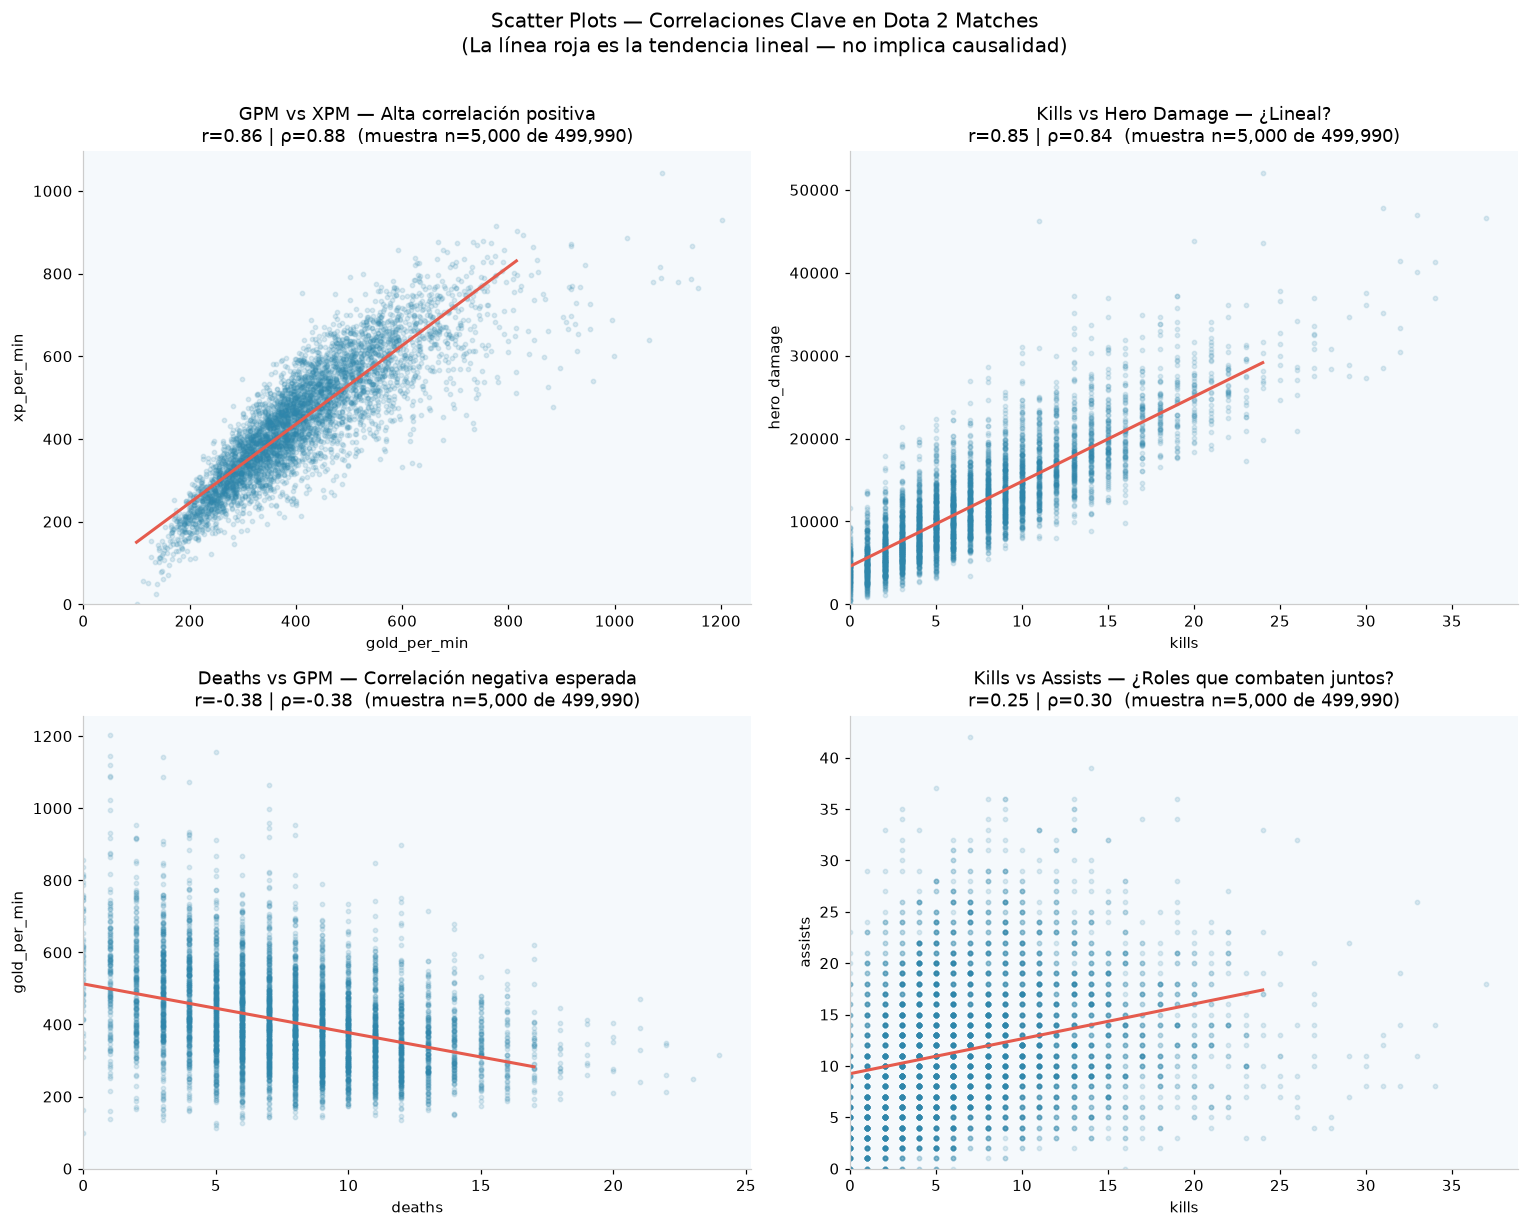


📌 PREGUNTAS:
  1. ¿GPM y XPM se correlacionan más que kills y damage? ¿Por qué?
  2. ¿La relación deaths–GPM es negativa? ¿Tiene sentido en el contexto del juego?
  3. ¿Hay alguna correlación que te parezca sorprendente? Explica una posible razón.


In [38]:
# ── Celda 9.2: Scatter plots de correlaciones clave ──────────────────────
pares_viz = [
    ('gold_per_min', 'xp_per_min',   'GPM vs XPM — Alta correlación positiva'),
    ('kills',        'hero_damage',  'Kills vs Hero Damage — ¿Lineal?'),
    ('deaths',       'gold_per_min', 'Deaths vs GPM — Correlación negativa esperada'),
    ('kills',        'assists',      'Kills vs Assists — ¿Roles que combaten juntos?'),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

# Muestra aleatoria para visualización (el dataset completo es muy grande)
df_sample = df.sample(n=5000, random_state=42)

for i, (x_col, y_col, title) in enumerate(pares_viz):
    r_val = df[x_col].corr(df[y_col])
    rho_val = df[x_col].corr(df[y_col], method='spearman')

    axes[i].scatter(df_sample[x_col], df_sample[y_col],
                    alpha=0.15, s=8, color=COLORS['steel'])

    # Línea de tendencia
    from numpy.polynomial.polynomial import polyfit
    p99x = df_sample[x_col].quantile(0.99)
    p99y = df_sample[y_col].quantile(0.99)
    mask_sub = (df_sample[x_col] <= p99x) & (df_sample[y_col] <= p99y)
    x_filt = df_sample.loc[mask_sub, x_col]
    y_filt = df_sample.loc[mask_sub, y_col]
    if len(x_filt) > 10:
        z = np.polyfit(x_filt, y_filt, 1)
        p_line = np.poly1d(z)
        x_line = np.linspace(x_filt.min(), x_filt.max(), 100)
        axes[i].plot(x_line, p_line(x_line), color=COLORS['coral'], linewidth=2)

    axes[i].set_xlabel(x_col)
    axes[i].set_ylabel(y_col)
    axes[i].set_title(f'{title}\nr={r_val:.2f} | ρ={rho_val:.2f}  '
                      f'(muestra n=5,000 de {len(df):,})')
    axes[i].set_xlim(left=0)
    axes[i].set_ylim(bottom=0)

fig.suptitle('Scatter Plots — Correlaciones Clave en Dota 2 Matches\n'
             '(La línea roja es la tendencia lineal — no implica causalidad)',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print()
print("📌 PREGUNTAS:")
print("  1. ¿GPM y XPM se correlacionan más que kills y damage? ¿Por qué?")
print("  2. ¿La relación deaths–GPM es negativa? ¿Tiene sentido en el contexto del juego?")
print("  3. ¿Hay alguna correlación que te parezca sorprendente? Explica una posible razón.")

---
## ⚖️ Sección 10 — Normalización de Variables — Control del Sesgo de Confusión

### El problema de las métricas brutas en Dota 2
Un jugador hizo **40,000 de daño** en una partida. ¿Es mucho o poco?

Depende de la duración: en una partida de 60 min, es inferior a 700 daño/min. En 20 min, son más de 2,000 daño/min — casi el triple de eficiencia.

**Usar hero_damage total para comparar jugadores de partidas de diferente duración es un sesgo de confusión.** La duración actúa como variable oculta que infla o desinfla las métricas absolutas.

### Solución: Métricas por minuto
```python
df['damage_pm'] = df['hero_damage'] / df['duracion_min']
df['kills_pm']  = df['kills']       / df['duracion_min']
```

### ¿Cuándo usar métricas brutas vs. normalizadas?
- **Brutas:** cuando la duración es constante o controlada (ej. partidas del mismo rango)
- **Normalizadas:** cuando comparas partidas de diferente duración (caso general)

In [39]:
# ── Celda 10.1: Crear métricas normalizadas por duración ─────────────────
df['kills_pm']   = df['kills']        / df['duracion_min']
df['deaths_pm']  = df['deaths']       / df['duracion_min']
df['assists_pm'] = df['assists']      / df['duracion_min']
df['damage_pm']  = df['hero_damage']  / df['duracion_min']
df['healing_pm'] = df['hero_healing'] / df['duracion_min']
df['tower_pm']   = df['tower_damage'] / df['duracion_min']

print("✅ Métricas normalizadas creadas:")
cols_norm = ['kills_pm','deaths_pm','assists_pm','damage_pm','healing_pm','tower_pm']
print(df[cols_norm].describe(percentiles=[.5,.75,.95]).round(3))

✅ Métricas normalizadas creadas:
        kills_pm  deaths_pm  assists_pm  damage_pm  healing_pm   tower_pm
count 499990.000 499990.000  499990.000 499990.000  499990.000 499990.000
mean       0.181      0.187       0.284    298.549      11.589     32.827
std        0.132      0.090       0.144    152.540      30.577     46.778
min        0.000      0.000       0.000      0.000       0.000      0.000
50%        0.153      0.180       0.267    271.718       0.000     13.419
75%        0.246      0.242       0.368    378.743       5.270     42.332
95%        0.432      0.345       0.546    584.868      70.788    135.192
max        2.740      1.984       2.134   2531.244     536.435    568.756


In [40]:
# ── Celda 10.2: Comparar métricas brutas vs. normalizadas por resultado ───
print("COMPARACIÓN — Métricas BRUTAS vs. NORMALIZADAS por resultado")
print("=" * 65)

print("\n── Métricas BRUTAS (sin normalizar):")
brutas = df.groupby('resultado')[['kills','deaths','hero_damage']].mean().round(2)
brutas.index = ['Perdedores','Ganadores']
display(brutas)

print("\n── Métricas NORMALIZADAS por minuto:")
norm = df.groupby('resultado')[['kills_pm','deaths_pm','damage_pm']].mean().round(4)
norm.index = ['Perdedores','Ganadores']
display(norm)

print()
print("📌 INTERPRETACIÓN:")
print("  • Si la diferencia relativa entre grupos cambia al normalizar → la duración")
print("    estaba confundiendo la relación original.")
print()

# Cohen's d para métricas brutas vs normalizadas
print("Cohen's d — antes y después de normalizar:")
for col_bruta, col_norm, nombre in [('kills','kills_pm','Kills'),
                                     ('hero_damage','damage_pm','Hero Damage')]:
    win_b  = df[df['resultado']=='win'][col_bruta].dropna()
    lose_b = df[df['resultado']=='lose'][col_bruta].dropna()
    win_n  = df[df['resultado']=='win'][col_norm].dropna()
    lose_n = df[df['resultado']=='lose'][col_norm].dropna()

    d_b = cohen_d(win_b, lose_b)
    d_n = cohen_d(win_n, lose_n)
    print(f"  {nombre:<15} d_bruto={d_b:.3f} | d_normalizado={d_n:.3f}")

COMPARACIÓN — Métricas BRUTAS vs. NORMALIZADAS por resultado

── Métricas BRUTAS (sin normalizar):


,kills,deaths,hero_damage
Perdedores,5.870,9.200,10850.280
Ganadores,8.940,6.160,13618.220



── Métricas NORMALIZADAS por minuto:


,kills_pm,deaths_pm,damage_pm
Perdedores,0.138,0.230,259.496
Ganadores,0.224,0.145,337.603



📌 INTERPRETACIÓN:
  • Si la diferencia relativa entre grupos cambia al normalizar → la duración
    estaba confundiendo la relación original.

Cohen's d — antes y después de normalizar:
  Kills           d_bruto=0.587 | d_normalizado=0.691
  Hero Damage     d_bruto=0.421 | d_normalizado=0.530


In [41]:
# ── Celda 10.3: Comparar métricas normalizadas por posición + resultado ───
print("MÉTRICAS NORMALIZADAS POR POSICIÓN Y RESULTADO")
print("=" * 60)

norm_pos = df.groupby(['pos_nombre', 'resultado'])[['kills_pm', 'damage_pm', 'gold_per_min']].mean()
norm_pos = norm_pos.round(4)

# Reordenar
try:
    norm_pos = norm_pos.reindex([(p, r) for p in orden_pos for r in ['lose','win']
                                  if p in norm_pos.index.get_level_values(0)])
except:
    pass

display(norm_pos)

print()
print("📌 PREGUNTA CRÍTICA:")
print("  ¿Las diferencias entre ganadores y perdedores se mantienen dentro de cada posición")
print("  después de normalizar? Si la diferencia cambia o desaparece en alguna posición,")
print("  eso sugiere que esa posición tiene factores distintos que afectan la relación.")

MÉTRICAS NORMALIZADAS POR POSICIÓN Y RESULTADO


kills_pm  damage_pm  gold_per_min
pos_nombre              resultado                                   
Slot 0 (aprox. carry)   lose          0.141    264.081       353.601
                        win           0.230    346.364       487.965
Slot 1 (aprox. mid)     lose          0.137    258.680       348.322
                        win           0.223    336.174       479.291
Slot 2 (aprox. offlane) lose          0.137    258.822       348.701
                        win           0.223    336.883       480.770
Slot 3 (aprox. support) lose          0.137    258.983       348.970
                        win           0.223    337.238       480.437
Slot 4 (aprox. support) lose          0.135    256.913       346.253
                        win           0.218    331.357       476.661


📌 PREGUNTA CRÍTICA:
  ¿Las diferencias entre ganadores y perdedores se mantienen dentro de cada posición
  después de normalizar? Si la diferencia cambia o desaparece en alguna posición,
  eso sugiere que esa posición tiene factores distintos que afectan la relación.


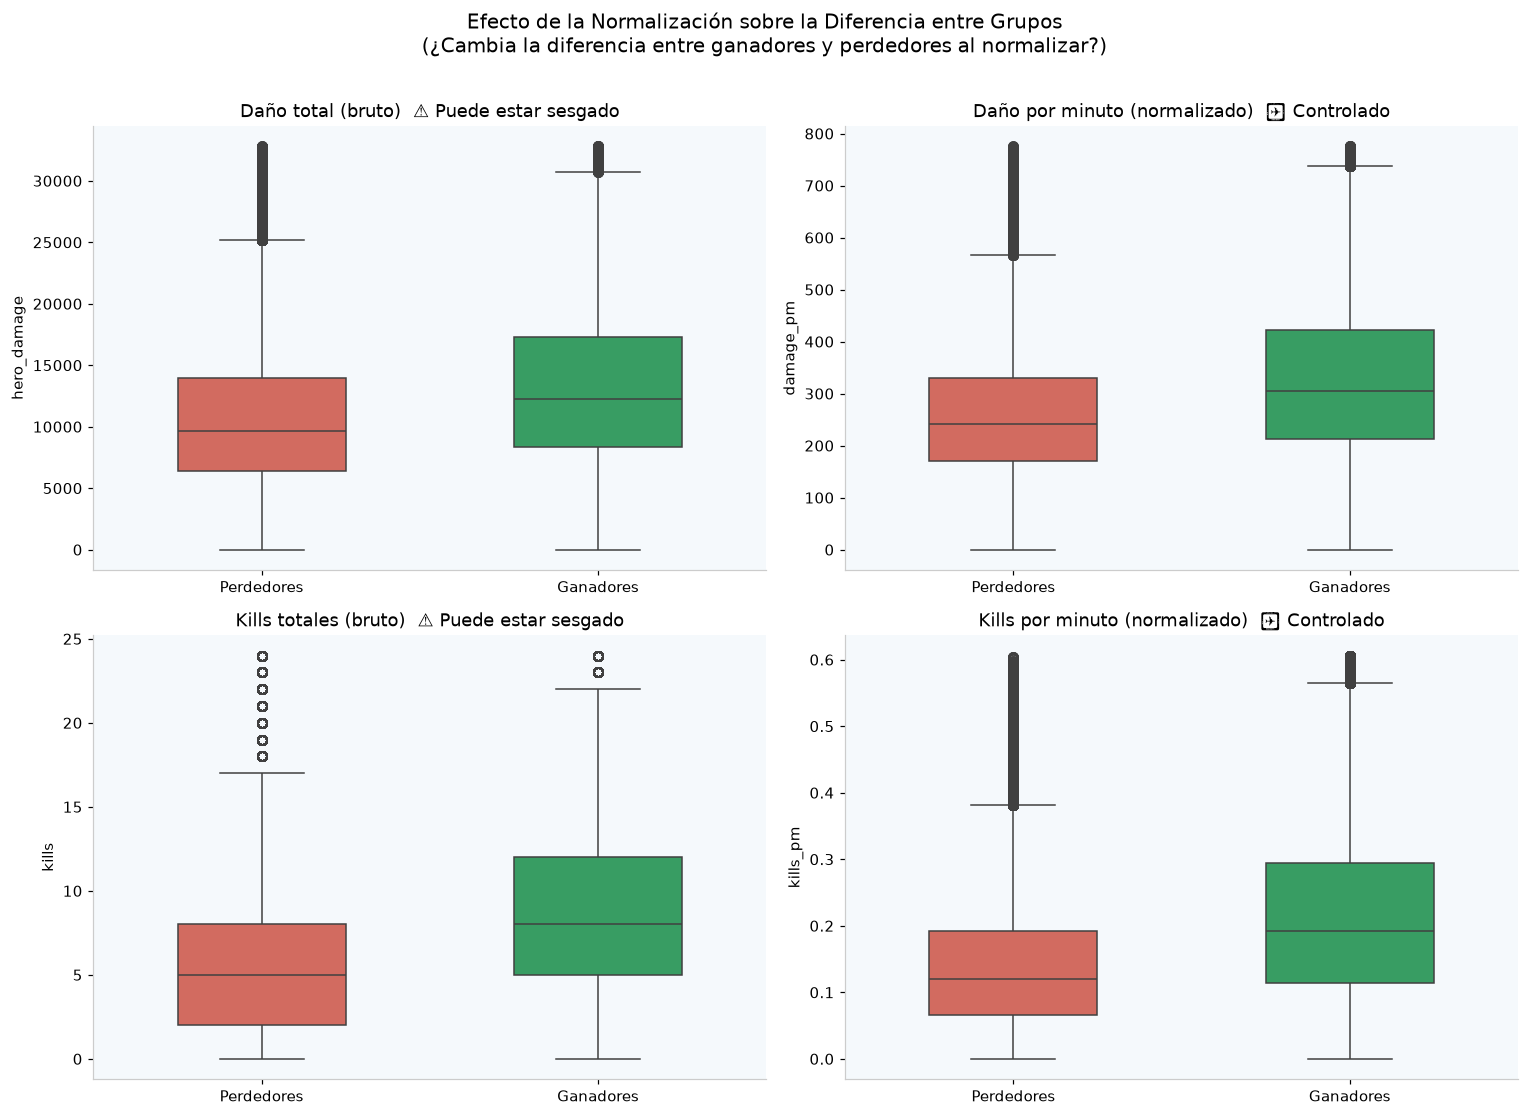

In [42]:
# ── Celda 10.4: Visualización — Efecto de la normalización ───────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metricas_pares = [
    ('hero_damage', 'damage_pm', 'Daño total (bruto)', 'Daño por minuto (normalizado)'),
    ('kills',       'kills_pm',  'Kills totales (bruto)', 'Kills por minuto (normalizado)'),
]

for row, (col_b, col_n, label_b, label_n) in enumerate(metricas_pares):
    for col_idx, (col, label) in enumerate([(col_b, label_b), (col_n, label_n)]):
        ax = axes[row][col_idx]
        p99 = df[col].quantile(0.99)
        df_viz = df[df[col] <= p99]
        sns.boxplot(data=df_viz, x='resultado', y=col,
                    palette={'win':COLORS['green'],'lose':COLORS['coral']},
                    ax=ax, order=['lose','win'], width=0.5)
        ax.set_title(label + ('  ⚠️ Puede estar sesgado' if col_idx==0 else '  ✅ Controlado'))
        ax.set_xticklabels(['Perdedores', 'Ganadores'])
        ax.set_xlabel('')

fig.suptitle('Efecto de la Normalización sobre la Diferencia entre Grupos\n'
             '(¿Cambia la diferencia entre ganadores y perdedores al normalizar?)',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

---
## 11. Capa Gold — productos analíticos

Gold contiene resultados agregados y reproducibles, no copias del detalle. Se generan tablas para responder preguntas concretas y alimentar el dashboard.

In [43]:
# Construir tablas Gold a partir de Silver
gold_resultado = (
    df.groupby("resultado", observed=True)
      .agg(
          jugadores=("match_id", "size"),
          partidas=("match_id", "nunique"),
          kills_media=("kills", "mean"),
          deaths_media=("deaths", "mean"),
          assists_media=("assists", "mean"),
          gpm_medio=("gold_per_min", "mean"),
          xpm_medio=("xp_per_min", "mean"),
          kda_medio=("kda_ratio", "mean"),
          damage_pm_medio=("damage_pm", "mean"),
      )
      .reset_index()
)

gold_heroes = (
    df.groupby(["hero_id", "localized_name"], observed=True)
      .agg(partidas=("match_id", "nunique"), victorias=("gano", "sum"), gpm_medio=("gold_per_min", "mean"))
      .reset_index()
)
gold_heroes["win_rate"] = gold_heroes["victorias"] / gold_heroes["partidas"]

gold_posicion = (
    df.groupby(["pos_nombre", "resultado"], observed=True)
      .agg(jugadores=("match_id", "size"), kills_pm=("kills_pm", "mean"), damage_pm=("damage_pm", "mean"), gpm=("gold_per_min", "mean"))
      .reset_index()
)

for filename, frame in {
    "kpis_por_resultado.csv": gold_resultado,
    "kpis_por_heroe.csv": gold_heroes,
    "kpis_por_slot_resultado.csv": gold_posicion,
}.items():
    frame.to_csv(GOLD_DIR / filename, index=False, encoding="utf-8-sig")

display(gold_resultado.round(3))
print(f"Gold listo: {GOLD_DIR.relative_to(PROJECT_ROOT)}")

,resultado,jugadores,partidas,kills_media,deaths_media,assists_media,gpm_medio,xpm_medio,kda_medio,damage_pm_medio
0,lose,249995,49999,5.872,9.204,9.435,349.169,395.629,1.609,259.496
1,win,249995,49999,8.936,6.156,14.088,481.025,504.329,4.259,337.603


Gold listo: data\gold\dota2


---
## 📈 Sección 11 — Dashboard EDA Completo

Visualización integrada de los principales hallazgos del análisis exploratorio en un solo panel de 6 gráficos.

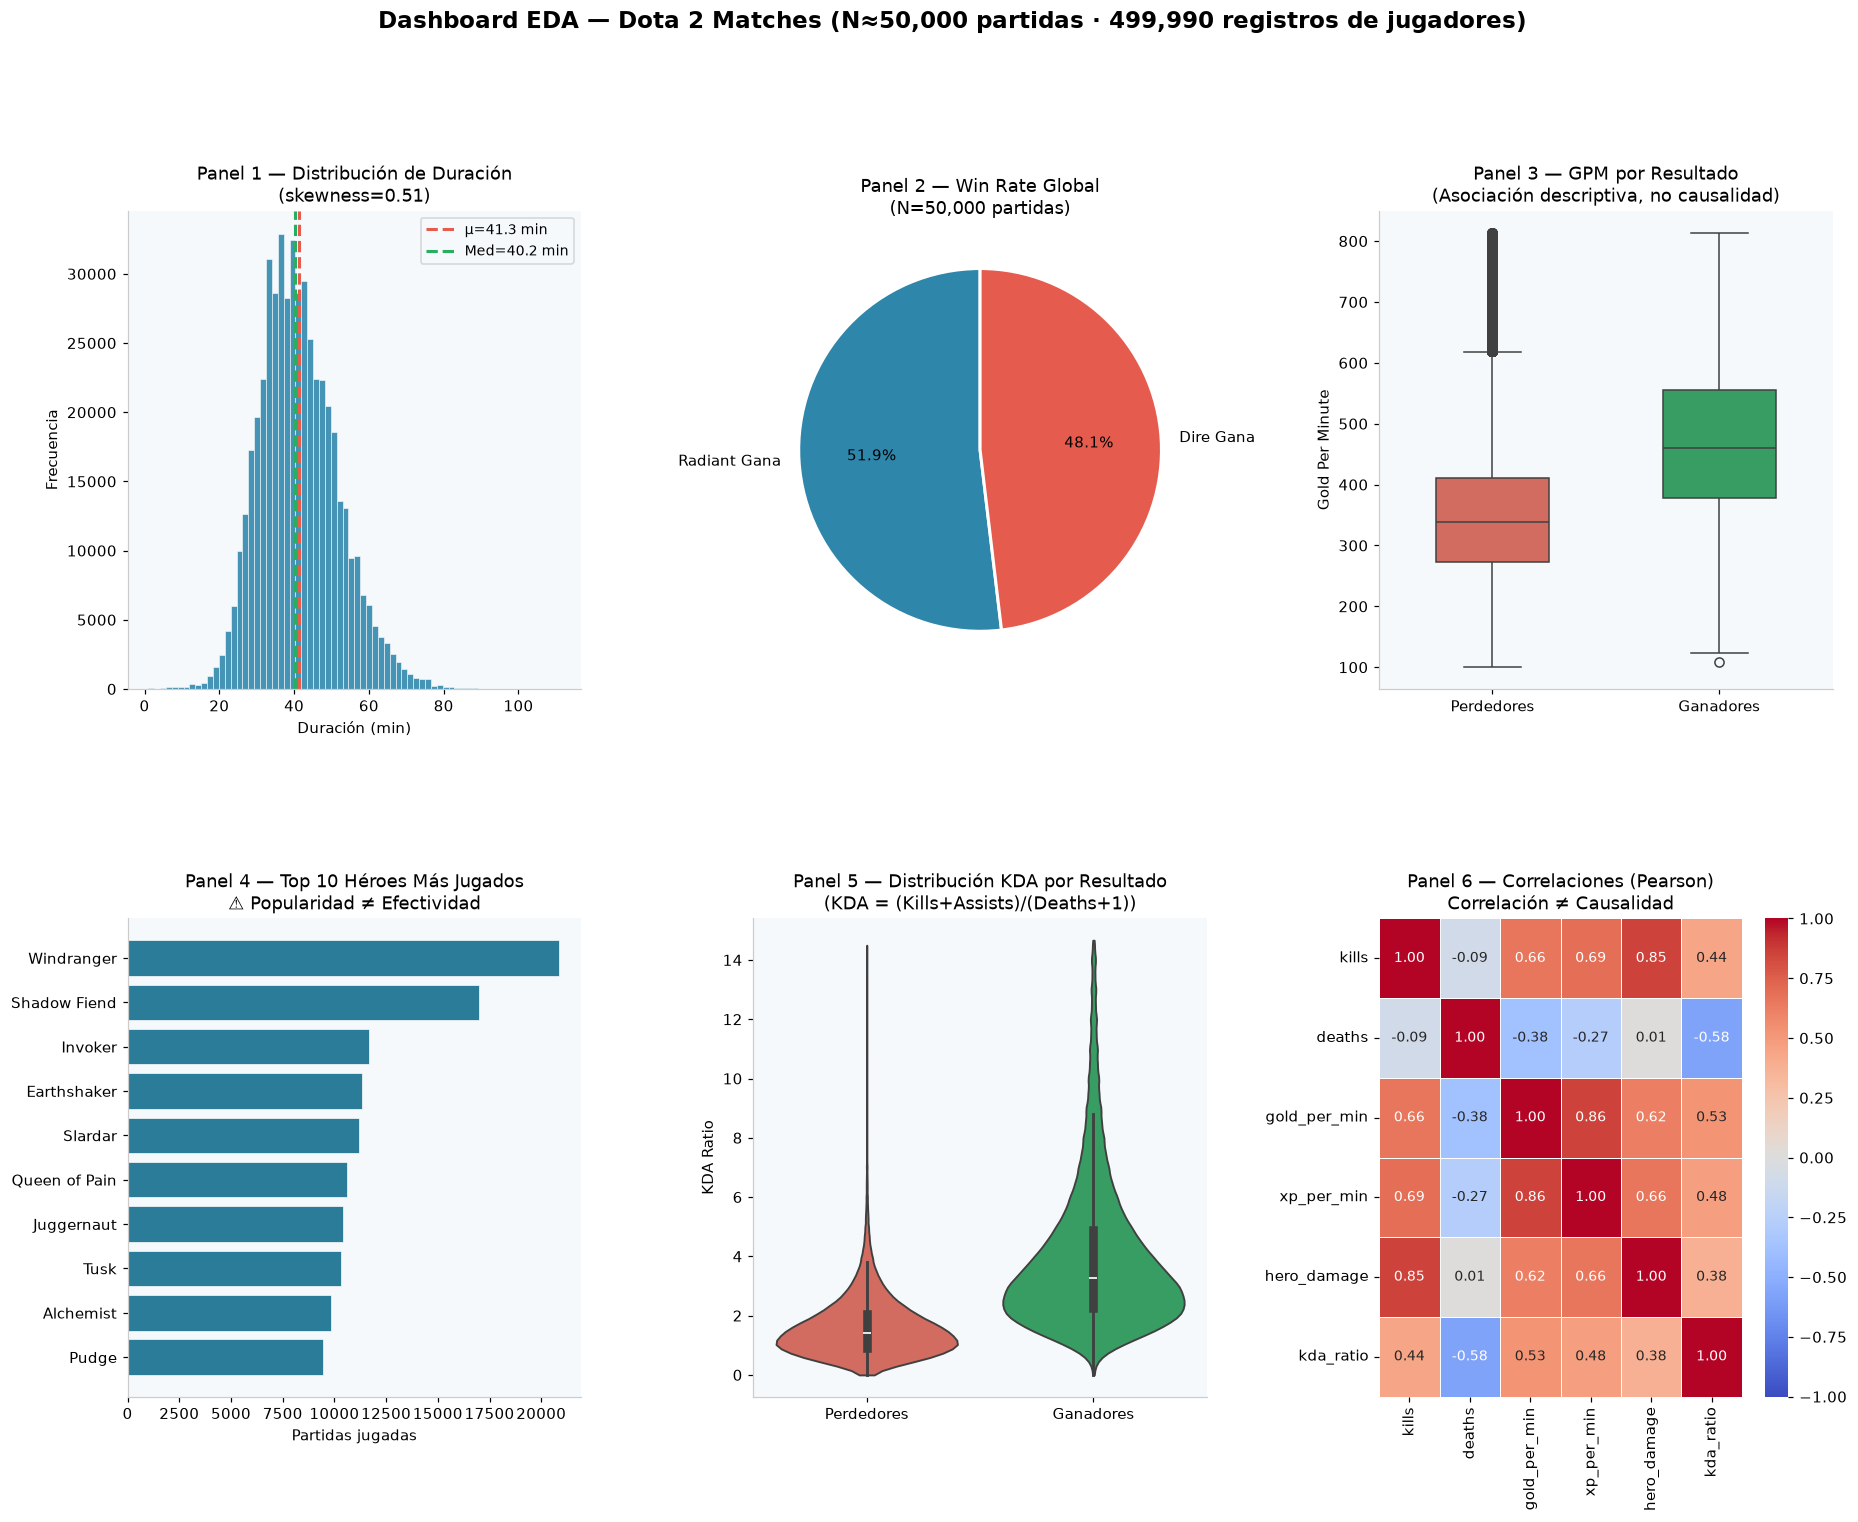

Dashboard guardado: C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\outputs\dota2\dashboard_eda_dota2.png


In [44]:
# ── Celda 11.1: Dashboard EDA — 6 paneles integrados ─────────────────────
fig = plt.figure(figsize=(20, 14))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.48, wspace=0.38)

# ── Panel 1: Distribución duración ────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(df['duracion_min'].dropna(), bins=70,
         color=COLORS['steel'], edgecolor='white', alpha=0.88, linewidth=0.4)
ax1.axvline(df['duracion_min'].mean(), color=COLORS['coral'], linestyle='--', lw=2,
            label=f"μ={df['duracion_min'].mean():.1f} min")
ax1.axvline(df['duracion_min'].median(), color=COLORS['green'], linestyle='--', lw=2,
            label=f"Med={df['duracion_min'].median():.1f} min")
ax1.set_xlabel('Duración (min)'); ax1.set_ylabel('Frecuencia')
ax1.set_title(f'Panel 1 — Distribución de Duración\n(skewness={df["duracion_min"].skew():.2f})')
ax1.legend(fontsize=9)

# ── Panel 2: Win Rate Global ──────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
wr = matches['radiant_win'].value_counts()
wedges, texts, autotexts = ax2.pie(
    wr.values, labels=['Radiant Gana', 'Dire Gana'],
    colors=[COLORS['steel'], COLORS['coral']],
    autopct='%1.1f%%', startangle=90,
    wedgeprops={'edgecolor':'white', 'linewidth':2}
)
ax2.set_title(f'Panel 2 — Win Rate Global\n(N={len(matches):,} partidas)')

# ── Panel 3: GPM Ganadores vs Perdedores ──────────────────────────────────
ax3 = fig.add_subplot(gs[0, 2])
p99_gpm = df['gold_per_min'].quantile(0.99)
df_gpm = df[df['gold_per_min'] <= p99_gpm]
sns.boxplot(data=df_gpm, x='resultado', y='gold_per_min',
            palette={'win':COLORS['green'],'lose':COLORS['coral']},
            ax=ax3, order=['lose','win'], width=0.5)
ax3.set_xticklabels(['Perdedores', 'Ganadores']); ax3.set_xlabel('')
ax3.set_ylabel('Gold Per Minute')
ax3.set_title('Panel 3 — GPM por Resultado\n(Asociación descriptiva, no causalidad)')

# ── Panel 4: Top 10 héroes más jugados ───────────────────────────────────
ax4 = fig.add_subplot(gs[1, 0])
top10_heroes = df['localized_name'].value_counts().head(10)
ax4.barh(top10_heroes.index[::-1], top10_heroes.values[::-1],
         color=COLORS['teal'], edgecolor='white', linewidth=0.5, alpha=0.88)
ax4.set_xlabel('Partidas jugadas')
ax4.set_title('Panel 4 — Top 10 Héroes Más Jugados\n⚠️ Popularidad ≠ Efectividad')

# ── Panel 5: KDA por resultado — violin plot ──────────────────────────────
ax5 = fig.add_subplot(gs[1, 1])
p99_kda = df['kda_ratio'].quantile(0.99)
df_kda = df[df['kda_ratio'] <= p99_kda]
sns.violinplot(data=df_kda, x='resultado', y='kda_ratio',
               palette={'win':COLORS['green'],'lose':COLORS['coral']},
               ax=ax5, order=['lose','win'], cut=0, inner='box')
ax5.set_xticklabels(['Perdedores', 'Ganadores']); ax5.set_xlabel('')
ax5.set_ylabel('KDA Ratio')
ax5.set_title('Panel 5 — Distribución KDA por Resultado\n(KDA = (Kills+Assists)/(Deaths+1))')

# ── Panel 6: Heatmap correlaciones ────────────────────────────────────────
ax6 = fig.add_subplot(gs[1, 2])
cols_heat = ['kills','deaths','gold_per_min','xp_per_min','hero_damage','kda_ratio']
corr_heat = df[cols_heat].corr()
sns.heatmap(corr_heat, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax6, linewidths=0.5,
            annot_kws={'size': 9}, vmin=-1, vmax=1)
ax6.set_title('Panel 6 — Correlaciones (Pearson)\nCorrelación ≠ Causalidad')

fig.suptitle(f'Dashboard EDA — Dota 2 Matches (N≈{len(matches):,} partidas · {len(df):,} registros de jugadores)',
             fontsize=15, fontweight='bold', y=1.01)
plt.savefig(OUTPUT_DIR / 'dashboard_eda_dota2.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print(f"Dashboard guardado: {OUTPUT_DIR / 'dashboard_eda_dota2.png'}")

---
## ⚠️ Sección 12 — Sesgos y Limitaciones del Análisis

Esta sección es **obligatoria** en todo análisis EDA responsable. Cada equipo debe identificar explícitamente los sesgos presentes en su análisis.

In [45]:
# ── Celda 12.1: Análisis de sesgos identificados ─────────────────────────
print("ANÁLISIS DE SESGOS DEL DATASET DOTA 2 MATCHES")
print("=" * 60)

sesgos = {
    "Sesgo de Selección": {
        "¿Está presente?": "SÍ",
        "Descripción": (
            "El dataset contiene partidas de un período específico "
            f"({matches['anio'].min()}–{matches['anio'].max()}), "
            "de servidores específicos y probablemente de cierto rango de habilidad. "
            "No representa todos los jugadores de Dota 2."
        ),
        "Pregunta clave": "¿A quién representa realmente este dataset?"
    },
    "Sesgo de Supervivencia": {
        "¿Está presente?": "POSIBLE",
        "Descripción": (
            f"El {(players['leaver_status'] > 0).mean()*100:.1f}% de los registros "
            "tienen leaver_status > 0 (jugador que abandonó). Si excluimos estas "
            "partidas sin analizar su impacto, podemos sesgar el análisis."
        ),
        "Pregunta clave": "¿Qué partidas o jugadores NO están representados en los datos?"
    },
    "Sesgo de Popularidad": {
        "¿Está presente?": "SÍ",
        "Descripción": (
            "Los héroes más populares tienen más victorias absolutas. "
            "Confundir victorias absolutas con win rate lleva a conclusiones incorrectas."
        ),
        "Pregunta clave": "¿Estoy mirando conteos absolutos o proporciones?"
    },
    "Sesgo de Confusión (Duración)": {
        "¿Está presente?": "SÍ",
        "Descripción": (
            "La duración de la partida confunde métricas absolutas: "
            "hero_damage, gold total, kills totales son más altos en partidas largas "
            "independientemente del desempeño. Solución: normalizar por minuto."
        ),
        "Pregunta clave": "¿Hay una tercera variable que explique la relación observada?"
    },
    "Paradoja de Simpson (Roles)": {
        "¿Está presente?": "SÍ",
        "Descripción": (
            "Comparar kills entre todas las posiciones mezcladas es engañoso. "
            "Un Carry promedia ~9 kills; un Hard Support promedia ~1-2 kills. "
            "El promedio global mezcla roles incomparables."
        ),
        "Pregunta clave": "¿Debo segmentar por posición, héroe o tipo de partida?"
    },
    "Sesgo Temporal (Patch del Juego)": {
        "¿Está presente?": "SÍ",
        "Descripción": (
            "La efectividad de los héroes cambia con cada actualización del juego (patch). "
            "El dataset puede reflejar una meta específica que ya no es actual."
        ),
        "Pregunta clave": "¿Los datos reflejan la versión actual del juego o una versión antigua?"
    },
}

for nombre, info in sesgos.items():
    estado = info['¿Está presente?']
    icono = '🔴' if estado == 'SÍ' else '🟡' if 'POSIBLE' in estado else '🟢'
    print(f"\n{icono} {nombre} [{estado}]")
    print(f"   {info['Descripción']}")
    print(f"   → {info['Pregunta clave']}")

# Cuantificar sesgo de supervivencia
leavers = players[players['leaver_status'] > 0]
print(f"\n📊 Registros con leaver_status > 0: {len(leavers):,} ({len(leavers)/len(players)*100:.1f}%)")

ANÁLISIS DE SESGOS DEL DATASET DOTA 2 MATCHES

🔴 Sesgo de Selección [SÍ]
   El dataset contiene partidas de un período específico (2015–2015), de servidores específicos y probablemente de cierto rango de habilidad. No representa todos los jugadores de Dota 2.
   → ¿A quién representa realmente este dataset?

🟡 Sesgo de Supervivencia [POSIBLE]
   El 2.4% de los registros tienen leaver_status > 0 (jugador que abandonó). Si excluimos estas partidas sin analizar su impacto, podemos sesgar el análisis.
   → ¿Qué partidas o jugadores NO están representados en los datos?

🔴 Sesgo de Popularidad [SÍ]
   Los héroes más populares tienen más victorias absolutas. Confundir victorias absolutas con win rate lleva a conclusiones incorrectas.
   → ¿Estoy mirando conteos absolutos o proporciones?

🔴 Sesgo de Confusión (Duración) [SÍ]
   La duración de la partida confunde métricas absolutas: hero_damage, gold total, kills totales son más altos en partidas largas independientemente del desempeño. Solució

---
## ✅ Sección 13 — Conclusiones Responsables

Toda conclusión de EDA debe seguir la plantilla de **4 componentes**:

```
1. HALLAZGO:             ¿Qué patrón observaste?
2. EVIDENCIA:            ¿Qué cálculo o visualización lo sustenta?
3. INTERPRETACIÓN:       ¿Qué sugiere? (sin afirmar causalidad)
4. LIMITACIÓN:           ¿Qué NO puede afirmarse y por qué?
```

> "El objetivo del EDA no es demostrar que tenemos razón; es descubrir qué preguntas merecen ser investigadas mejor." — Semana 06, UNAJ 2026-2

In [46]:
# ── Celda 13.1: Generación automática de conclusiones con evidencia ───────

# Calcular valores para las conclusiones
gpm_win  = df[df['resultado']=='win']['gold_per_min'].mean()
gpm_lose = df[df['resultado']=='lose']['gold_per_min'].mean()
gpm_diff = (gpm_win - gpm_lose) / gpm_lose * 100

kda_win  = df[df['resultado']=='win']['kda_ratio'].mean()
kda_lose = df[df['resultado']=='lose']['kda_ratio'].mean()
kda_diff = (kda_win - kda_lose) / kda_lose * 100

# Cohen's d para GPM: reutiliza la misma definición con desviación combinada
d_gpm = cohen_d(
    df.loc[df['resultado'] == 'win', 'gold_per_min'],
    df.loc[df['resultado'] == 'lose', 'gold_per_min'],
)
mag_gpm = magnitud_cohen(d_gpm).lower()

wr_radiant = matches['radiant_win'].mean() * 100
skew_dur = df['duracion_min'].skew()

print("╔══════════════════════════════════════════════════════════════════╗")
print("║              CONCLUSIONES RESPONSABLES — SEMANA 06              ║")
print("║          Análisis EDA: Dota 2 Matches — Kaggle (2016)           ║")
print("╚══════════════════════════════════════════════════════════════════╝")

conclusiones = [
    {
        "n": 1,
        "Hallazgo": f"Los jugadores ganadores tienen mayor gold_per_min promedio ({gpm_win:.0f}) que los perdedores ({gpm_lose:.0f})",
        "Evidencia": f"Diferencia relativa = {gpm_diff:.1f}%. Cohen's d = {d_gpm:.3f} (efecto {mag_gpm}).",
        "Interpretación": "Existe una asociación entre eficiencia económica y resultado de la partida en este dataset.",
        "Limitación": ("No podemos afirmar causalidad: el gold_per_min final puede ser consecuencia "
                       "de ir ganando (jugadores de un equipo ganador tienen más oportunidades de farmear). "
                       "Confusores posibles: posición del jugador, héroe, patch del juego.")
    },
    {
        "n": 2,
        "Hallazgo": f"Los jugadores ganadores tienen un KDA ratio promedio de {kda_win:.2f} vs. {kda_lose:.2f} de los perdedores",
        "Evidencia": f"Diferencia relativa = {kda_diff:.1f}%. El KDA considera kills, assists y deaths simultáneamente.",
        "Interpretación": "Un mejor desempeño de combate (más efectivo, menos muerto) se asocia con victoria.",
        "Limitación": ("El KDA varía enormemente por posición: comparar el KDA de un Carry con el de un Support "
                       "es injusto por diseño del juego. Además, un equipo que ya va ganando puede 'farmear' "
                       "más kills seguros, inflando el KDA como consecuencia, no como causa.")
    },
    {
        "n": 3,
        "Hallazgo": f"La distribución de duración de partidas tiene skewness = {skew_dur:.2f} (cola derecha)",
        "Evidencia": f"Media = {df['duracion_min'].mean():.1f} min > Mediana = {df['duracion_min'].median():.1f} min. P95 = {df['duracion_min'].quantile(0.95):.0f} min.",
        "Interpretación": "La mayoría de partidas dura entre 35-55 minutos, pero partidas largas existen como atípicos superiores.",
        "Limitación": ("La duración actúa como variable confusora: no normalizar métricas por minuto "
                       "lleva a comparaciones injustas entre partidas de diferente duración.")
    },
    {
        "n": 4,
        "Hallazgo": f"El equipo Radiant gana el {wr_radiant:.1f}% de las partidas del dataset",
        "Evidencia": f"De {len(matches):,} partidas, {matches['radiant_win'].sum():,} fueron ganadas por Radiant.",
        "Interpretación": "Existe una ligera ventaja de Radiant en el dataset analizado.",
        "Limitación": ("No podemos afirmar que Radiant 'siempre gana más' porque: (1) el dataset es "
                       "de un período específico, (2) la ventaja puede reflejar diferencias de mapa "
                       "del juego en ese patch, y (3) puede estar sesgado por el rango de los jugadores "
                       "incluidos en el dataset.")
    },
]

for c in conclusiones:
    print(f"\n{'─'*68}")
    print(f"CONCLUSIÓN {c['n']}")
    print(f"  HALLAZGO:       {c['Hallazgo']}")
    print(f"  EVIDENCIA:      {c['Evidencia']}")
    print(f"  INTERPRETACIÓN: {c['Interpretación']}")
    print(f"  LIMITACIÓN:     {c['Limitación']}")

╔══════════════════════════════════════════════════════════════════╗
║              CONCLUSIONES RESPONSABLES — SEMANA 06              ║
║          Análisis EDA: Dota 2 Matches — Kaggle (2016)           ║
╚══════════════════════════════════════════════════════════════════╝

────────────────────────────────────────────────────────────────────
CONCLUSIÓN 1
  HALLAZGO:       Los jugadores ganadores tienen mayor gold_per_min promedio (481) que los perdedores (349)
  EVIDENCIA:      Diferencia relativa = 37.8%. Cohen's d = 1.085 (efecto grande).
  INTERPRETACIÓN: Existe una asociación entre eficiencia económica y resultado de la partida en este dataset.
  LIMITACIÓN:     No podemos afirmar causalidad: el gold_per_min final puede ser consecuencia de ir ganando (jugadores de un equipo ganador tienen más oportunidades de farmear). Confusores posibles: posición del jugador, héroe, patch del juego.

────────────────────────────────────────────────────────────────────
CONCLUSIÓN 2
  HALLAZGO:    

---
## 🏁 Plantilla de Conclusión para los Equipos

Completa esta plantilla con los hallazgos de tu equipo. Cada equipo debe elegir **una pregunta** de la actividad y responderla responsablemente:

```markdown
## Conclusión responsable — [Nombre del Equipo]

**Pregunta de investigación:** ¿[pregunta elegida por el equipo]?

**En este análisis observamos que** ________ **se relaciona con** ________.

**La evidencia principal fue** ________ [incluir estadístico o visualización].

**Esto sugiere que** ________ [interpretación moderada, sin afirmar causalidad].

**Sin embargo, no podemos afirmar causalidad porque** ________ [razón técnica].

**Una posible variable de confusión es** ________ [variable específica del dataset].

**Para profundizar, sería necesario analizar** ________ [próximo paso concreto].

**Sesgo identificado:** ________ [nombrar el tipo de sesgo y cómo afecta la conclusión].
```

---

## 🔮 Conexión con la Semana 07

En la **Semana 07** convertiremos los features derivados hoy en un problema de **Machine Learning supervisado**:
- **Tarea:** Clasificación binaria — predecir si un equipo gana (`radiant_win`)
- **Features:** `gold_per_min`, `xp_per_min`, `kills_pm`, `damage_pm`, `kda_ratio`, `duracion_min`
- **Modelos:** Regresión Logística, Random Forest, XGBoost
- **Métricas:** AUC-ROC, F1-Score, Matriz de Confusión

> El EDA que hiciste hoy es el fundamento del modelado de mañana. Sin entender los datos, ningún modelo puede construirse de forma responsable. (Géron, 2019)

---

*Universidad Nacional de Juliaca — UNAJ | Big Data Semana 06 | Docente: Mg. Leibnihtz Abrahan Ayamamani Choque | 2026-2*